# NASA CMAPSS FD001 — Predicción de Vida Útil Remanente (RUL)

**Dataset:** NASA Turbofan Engine Degradation Simulation (Kaggle `behrad3d/nasa-cmaps`, `archive/CMaps/`)
- `train_FD001.txt` — 100 motores operados hasta el fallo catastrófico (*run-to-failure*).
- `test_FD001.txt` — 100 motores con series temporales truncadas en un ciclo arbitrario antes del fallo.
- `RUL_FD001.txt` — RUL remanente real de cada uno de los 100 motores de test desde su último ciclo registrado.

**Objetivo:** Desarrollar y comparar un pipeline de mantenimiento predictivo riguroso de extremo a extremo, evaluando modelos tabulares (XGBoost con memoria temporal) y redes recurrentes (LSTM regularizada) bajo el protocolo y métricas oficiales de la literatura de la NASA.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')


## 1. Carga de datos

El dataset no incluye encabezados. Definimos las 26 columnas canónicas:
- `engine_id`: Identificador de la unidad turbofán.
- `cycle`: Ciclo de vuelo/operación (secuencia temporal).
- `setting1`, `setting2`, `setting3`: Ajustes de condiciones operativas de vuelo.
- `s1`…`s21`: 21 mediciones de sensores distribuidos a lo largo del turbofán (presiones, temperaturas, velocidades de rotor, relaciones de flujo).

> **Principio de consistencia temporal:** En `train`, los motores finalizan en fallo ($RUL=0$). En `test`, la serie se interrumpe antes del fallo y los ciclos restantes exactos se encuentran en `RUL_FD001.txt`.

In [2]:
COLS = ['engine_id', 'cycle', 'setting1', 'setting2', 'setting3'] + [f's{i}' for i in range(1, 22)]

train = pd.read_csv('archive/CMaps/train_FD001.txt', sep=r'\s+', header=None, names=COLS)
test  = pd.read_csv('archive/CMaps/test_FD001.txt',  sep=r'\s+', header=None, names=COLS)
rul   = pd.read_csv('archive/CMaps/RUL_FD001.txt',  sep=r'\s+', header=None, names=['RUL'])

print(f'train shape: {train.shape} ({train["engine_id"].nunique()} motores)')
print(f'test  shape: {test.shape} ({test["engine_id"].nunique()} motores)')
print(f'rul   shape: {rul.shape} (1 valor por motor de test)')
display(train.head(3))


train shape: (20631, 26) (100 motores)
test  shape: (13096, 26) (100 motores)
rul   shape: (100, 1) (1 valor por motor de test)


,engine_id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


## 2. EDA — ¿Qué tenemos realmente?

Analizamos la distribución de ciclos de vida, la varianza de cada sensor para detectar variables sin señal y las correlaciones físicas entre subsistemas de la turbina.

In [3]:
# Distribución de ciclos y duración hasta fallo en train
n_motores_train = train['engine_id'].nunique()
n_ciclos_train  = len(train)

ciclos_por_motor = train.groupby('engine_id')['cycle'].agg(['min', 'max', 'count'])
ciclos_por_motor['duracion'] = ciclos_por_motor['max'] - ciclos_por_motor['min'] + 1

print(f'Motores en train: {n_motores_train}')
print(f'Ciclos totales en train: {n_ciclos_train}')
print(f'Duración por motor — mín: {ciclos_por_motor["duracion"].min()}, ' 
      f'máx: {ciclos_por_motor["duracion"].max()}, ' 
      f'media: {ciclos_por_motor["duracion"].mean():.1f} ciclos')
display(ciclos_por_motor.head())


Motores en train: 100
Ciclos totales en train: 20631
Duración por motor — mín: 128, máx: 362, media: 206.3 ciclos


,min,max,count,duracion
engine_id,,,,
1,1,192,192,192
2,1,287,287,287
3,1,179,179,179
4,1,189,189,189
5,1,269,269,269


Variables constantes en train (7): ['s1', 's5', 's10', 's16', 's18', 's19', 'setting3']
Variables constantes en test  (7): ['s1', 's5', 's10', 's16', 's18', 's19', 'setting3']

Sensores activos informativos (15): ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


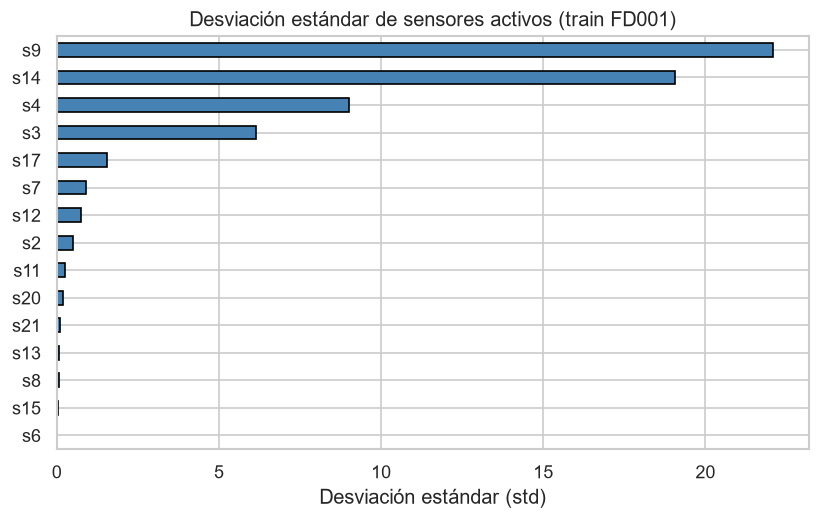

In [4]:
# Diferenciación rigurosa: Settings vs Sensores
SETTINGS_COLS = ['setting1', 'setting2', 'setting3']
SENSOR_COLS   = [f's{i}' for i in range(1, 22)]

# Identificación formal de variables sin varianza (desviación estándar = 0)
constante_train = [c for c in SENSOR_COLS + SETTINGS_COLS if train[c].nunique() == 1]
constante_test  = [c for c in SENSOR_COLS + SETTINGS_COLS if test[c].nunique() == 1]

print(f'Variables constantes en train ({len(constante_train)}): {constante_train}')
print(f'Variables constantes en test  ({len(constante_test)}): {constante_test}')

# Selección de los 14 sensores informativos activos con señal de degradación física
ACTIVE_SENSORS = [c for c in SENSOR_COLS if c not in constante_train]
print(f'\nSensores activos informativos ({len(ACTIVE_SENSORS)}): {ACTIVE_SENSORS}')

variabilidad = train[ACTIVE_SENSORS].std().sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
variabilidad.plot(kind='barh', color='steelblue', edgecolor='black', ax=ax)
ax.set_title('Desviación estándar de sensores activos (train FD001)')
ax.set_xlabel('Desviación estándar (std)')
plt.tight_layout()
plt.show()


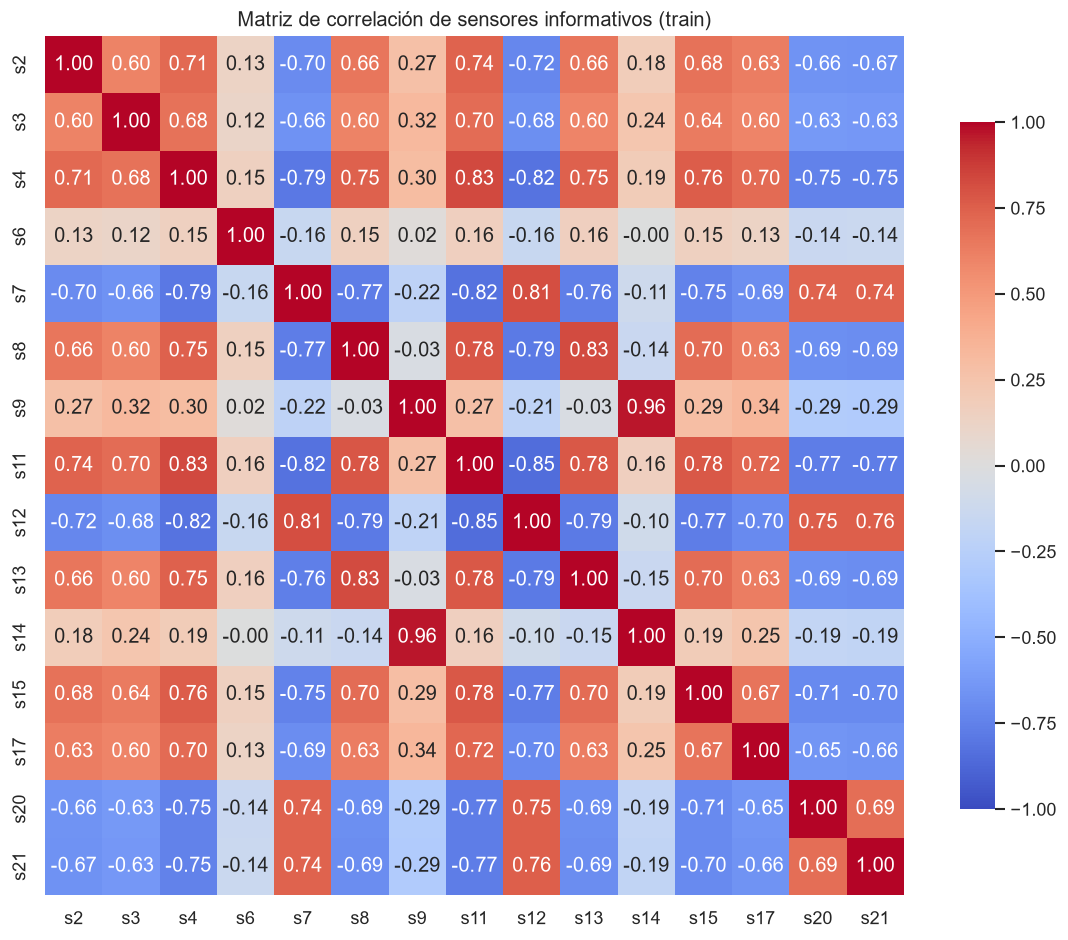

Pares altamente colineales (|r| > 0.9): 1
  s9   — s14 : r = 0.963

Nota termodinámica: s9 (HPC outlet temperature) y s14 (LPT rotor speed) presentan r = 0.963 debido al acoplamiento físico en la turbina de gas: al degradarse el compresor de alta, la turbina de baja debe acelerar para compensar la caída de rendimiento, incrementando conjuntamente temperatura y velocidad.


In [5]:
# Correlación física e interdependencia entre sensores activos
corr = train[ACTIVE_SENSORS].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', 
            ax=ax, square=True, cbar_kws={'shrink': 0.8})
ax.set_title('Matriz de correlación de sensores informativos (train)')
plt.tight_layout()
plt.show()

# Identificación de pares con colinealidad extrema (|r| > 0.9)
pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        v = corr.iloc[i, j]
        if abs(v) > 0.9:
            pairs.append((corr.columns[i], corr.columns[j], round(v, 3)))

print(f'Pares altamente colineales (|r| > 0.9): {len(pairs)}')
for p in pairs:
    print(f'  {p[0]:4s} — {p[1]:4s}: r = {p[2]}')
print('\nNota termodinámica: s9 (HPC outlet temperature) y s14 (LPT rotor speed) presentan r = 0.963 ' 
      'debido al acoplamiento físico en la turbina de gas: al degradarse el compresor de alta, la turbina de baja ' 
      'debe acelerar para compensar la caída de rendimiento, incrementando conjuntamente temperatura y velocidad.')


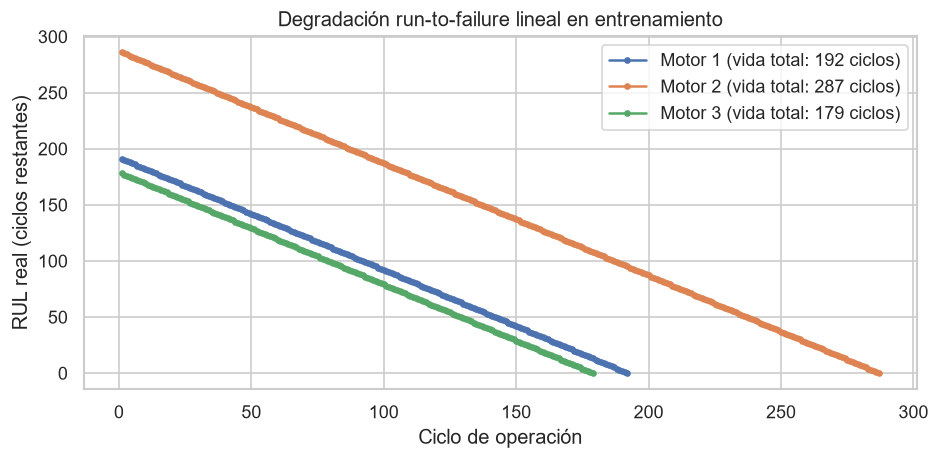

In [6]:
# Dinámica de degradación: RUL vs Ciclo en 3 motores de entrenamiento
train_sample = train[train['engine_id'].isin([1, 2, 3])].copy()
max_cycle = train_sample.groupby('engine_id')['cycle'].transform('max')
train_sample['RUL'] = max_cycle - train_sample['cycle']

fig, ax = plt.subplots(figsize=(8, 4))
for eid in [1, 2, 3]:
    sub = train_sample[train_sample['engine_id'] == eid]
    ax.plot(sub['cycle'], sub['RUL'], marker='.', label=f'Motor {eid} (vida total: {len(sub)} ciclos)')
ax.set_xlabel('Ciclo de operación')
ax.set_ylabel('RUL real (ciclos restantes)')
ax.set_title('Degradación run-to-failure lineal en entrenamiento')
ax.legend()
plt.tight_layout()
plt.show()


## 3. Preprocesamiento Riguroso y Reconstrucción del Target

### Reglas Metodológicas Clave:
1. **Cálculo exacto del objetivo (`RUL`) en Test:**
   - En `train`: los motores alcanzan el fallo al término de la serie ($RUL = \max(ciclo) - ciclo$).
   - En `test`: la serie se corta antes del fallo. El archivo `RUL_FD001.txt` contiene los ciclos que le restaban a cada motor en su último ciclo observado ($ciclo_{max}$). Por tanto, el ciclo real de fallo es $ciclo_{fallo} = ciclo_{max} + RUL_{FD001}[engine\_id]$, y el RUL en cada instante $t$ es $RUL(t) = ciclo_{fallo} - t$.
2. **Piecewise Linear RUL (Clipping a 125 ciclos):**
   - Durante las primeras etapas operativas el motor no presenta degradación medible. En la literatura estándar de CMAPSS (Heimes, 2008), recortar a 125 ciclos evita que los modelos intenten predecir diferencias aleatorias en un estado de salud 100% óptimo.
3. **Filtrado de variables sin varianza:**
   - Se descartan las 7 columnas constantes identificadas en el EDA, reteniendo exclusivamente los 14 sensores informativos activos.
4. **Prevención de Data Leakage:**
   - El `StandardScaler` se ajusta (`fit=True`) **única y exclusivamente** con los datos de `train`. Los datos de `test` se normalizan mediante `transform` con los parámetros aprendidos.

In [7]:
CLIP = 125
from sklearn.preprocessing import StandardScaler

def prepare(df, rul_df=None, scaler=None, fit=False, feature_cols=ACTIVE_SENSORS):
    """
    Prepara las features y el target RUL garantizando cero data leakage.
    Para test, incorpora el RUL remanente oficial de RUL_FD001.txt.
    """
    df = df.copy()
    max_cycle = df.groupby('engine_id')['cycle'].transform('max')
    
    if rul_df is not None:
        # En test: sumamos el RUL remanente real de RUL_FD001.txt a cada motor
        rul_map = dict(zip(range(1, len(rul_df) + 1), rul_df['RUL'].values))
        true_max_cycle = max_cycle + df['engine_id'].map(rul_map)
        df['RUL'] = (true_max_cycle - df['cycle']).clip(upper=CLIP)
    else:
        # En train: el motor llega hasta el fallo (RUL = 0 al final)
        df['RUL'] = (max_cycle - df['cycle']).clip(upper=CLIP)
        
    X = df[feature_cols].values
    if fit:
        scaler = scaler.fit(X)
    X_scaled = scaler.transform(X)
    y = df['RUL'].values
    meta = df[['engine_id', 'cycle']].copy()
    meta['RUL'] = y
    return X_scaled, y, meta, scaler

scaler = StandardScaler()
X_train, y_train, meta_train, scaler = prepare(train, scaler=scaler, fit=True)
X_test,  y_test,  meta_test,  _       = prepare(test,  rul_df=rul, scaler=scaler, fit=False)

print(f'Features activas seleccionadas: {len(ACTIVE_SENSORS)} sensores')
print(f'X_train shape: {X_train.shape} | y_train — mín {y_train.min():.0f}, media {y_train.mean():.1f}, máx {y_train.max():.0f}')
print(f'X_test  shape: {X_test.shape}  | y_test  — mín {y_test.min():.0f}, media {y_test.mean():.1f}, máx {y_test.max():.0f}')


Features activas seleccionadas: 15 sensores
X_train shape: (20631, 15) | y_train — mín 0, media 86.8, máx 125
X_test  shape: (13096, 15)  | y_test  — mín 7, media 108.9, máx 125


## 4. Ventanas Temporales para Modelos Secuenciales

Para capturar la dinámica temporal y la tasa de degradación, transformamos las series en ventanas deslizantes de longitud $W=30$ ciclos:
- Cada muestra tiene dimensión `(30, 14)`.
- El target `y` es el RUL del **último ciclo** de la ventana.
- **Padding robusto:** Si un motor tuviese menos de 30 ciclos, se replica el ciclo inicial en lugar de descartarlo (garantiza compatibilidad total con cualquier motor).
- **Validación sin Data Leakage:** El particionado (80% train / 20% val) se realiza **por motor completo (`engine_id`)** antes de construir las ventanas, garantizando que un motor nunca esté simultáneamente en entrenamiento y validación.

In [8]:
WINDOW = 30

def build_windows(X, y, meta, window=WINDOW, last_only=False):
    """
    Genera secuencias temporales de longitud `window` por motor con soporte de padding.
    Si last_only=True, extrae únicamente la última ventana disponible de cada motor.
    """
    X_list, y_list, meta_rows = [], [], []
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    df_meta = meta.reset_index(drop=True)
    
    for eid in np.unique(df_meta['engine_id'].values):
        idx = np.where(df_meta['engine_id'].values == eid)[0]
        seg_X = X[idx]
        seg_y = y[idx]
        seg_c = df_meta.loc[idx, 'cycle'].values
        n_pts = len(seg_X)
        
        # Si el motor tiene menos ciclos que window, aplicar padding replicando el primer ciclo
        if n_pts < window:
            pad_len = window - n_pts
            pad_x = np.repeat(seg_X[0:1], pad_len, axis=0)
            seg_X = np.vstack([pad_x, seg_X])
            seg_y = np.pad(seg_y, (pad_len, 0), mode='edge')
            seg_c = np.pad(seg_c, (pad_len, 0), mode='edge')
            n_pts = window
            
        if last_only:
            X_list.append(seg_X[-window:])
            y_list.append(seg_y[-1])
            meta_rows.append({'engine_id': int(eid), 'last_cycle': int(seg_c[-1]), 'RUL_real': float(seg_y[-1])})
        else:
            for i in range(n_pts - window + 1):
                X_list.append(seg_X[i:i + window])
                y_list.append(seg_y[i + window - 1])
                meta_rows.append({'engine_id': int(eid), 'last_cycle': int(seg_c[i + window - 1]), 'RUL_real': float(seg_y[i + window - 1])})
                
    return np.array(X_list), np.array(y_list), pd.DataFrame(meta_rows)

# Split 80/20 por motor en entrenamiento
rng = np.random.RandomState(42)
engine_ids = np.unique(meta_train['engine_id'])
perm = rng.permutation(len(engine_ids))
n_val = int(round(0.2 * len(engine_ids)))
val_ids = set(engine_ids[perm[:n_val]])

mask_tr = ~meta_train['engine_id'].isin(val_ids).values
mask_va =  meta_train['engine_id'].isin(val_ids).values

X_train_w, y_train_w, meta_train_w = build_windows(X_train[mask_tr], y_train[mask_tr], meta_train[mask_tr], window=WINDOW)
X_val_w,   y_val_w,   meta_val_w   = build_windows(X_train[mask_va], y_train[mask_va], meta_train[mask_va], window=WINDOW)
X_test_w_all, y_test_w_all, meta_test_w_all = build_windows(X_test, y_test, meta_test, window=WINDOW, last_only=False)
X_test_w_last, y_test_w_last, meta_test_w_last = build_windows(X_test, y_test, meta_test, window=WINDOW, last_only=True)

print(f'Partición por motores: {len(engine_ids) - n_val} train / {n_val} validación')
print(f'Ventanas train: {X_train_w.shape} | Ventanas val: {X_val_w.shape}')
print(f'Ventanas test (todas): {X_test_w_all.shape}')
print(f'Ventanas test (última por motor): {X_test_w_last.shape} (exactamente 100 motores)')


Partición por motores: 80 train / 20 validación
Ventanas train: (14241, 30, 15) | Ventanas val: (3490, 30, 15)
Ventanas test (todas): (10196, 30, 15)
Ventanas test (última por motor): (100, 30, 15) (exactamente 100 motores)


## 5. Baseline ML — XGBoost con Memoria Temporal

### Un Baseline Justo y Competitivo
Evaluar un modelo de gradiente sobre ciclos aislados ($t$) es metodológicamente injusto frente a la LSTM, ya que los sensores de turbofanes contienen ruido Gaussiano inherente que produce oscilaciones erráticas en árboles de decisión.

Para nivelar el terreno, dotamos a XGBoost de memoria temporal mediante:
- **Medias móviles** (*rolling mean* a 5 y 10 ciclos por motor).
- **Desviaciones estándar móviles** (*rolling std* a 5 y 10 ciclos por motor).

### Función Oficial de Puntuación CMAPSS (NASA Score Asimétrico)
En la competición oficial PHM 2008 / CMAPSS, el error no es simétrico. Un error tardío ($d = \hat{y} - y > 0$, sobreestimar el RUL) puede provocar un fallo catastrófico en vuelo, por lo que se penaliza exponencialmente con base 10; un error temprano ($d < 0$, subestimar el RUL) solo adelanta una inspección preventiva y se penaliza con base 13:

$$s_i = \begin{cases} e^{-d_i / 13} - 1 & \text{si } d_i < 0 \\ e^{d_i / 10} - 1 & \text{si } d_i \ge 0 \end{cases}, \quad S = \sum_{i=1}^{100} s_i$$

In [9]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import joblib

def nasa_score(y_true, y_pred):
    """Métrica oficial asimétrica de la NASA para CMAPSS."""
    d = np.asarray(y_pred) - np.asarray(y_true)
    score = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(score))

# Generación de features temporales para XGBoost
def extract_rolling_features(df, sensor_cols=ACTIVE_SENSORS):
    feats = [df[sensor_cols]]
    for w in [5, 10]:
        rmean = df.groupby('engine_id')[sensor_cols].rolling(w, min_periods=1).mean().reset_index(level=0, drop=True)
        rmean.columns = [f'{c}_rmean_{w}' for c in sensor_cols]
        rstd = df.groupby('engine_id')[sensor_cols].rolling(w, min_periods=1).std().fillna(0).reset_index(level=0, drop=True)
        rstd.columns = [f'{c}_rstd_{w}' for c in sensor_cols]
        feats.extend([rmean, rstd])
    return pd.concat(feats, axis=1)

X_train_tab = extract_rolling_features(train)
X_test_tab  = extract_rolling_features(test)

scaler_tab = StandardScaler()
X_train_tab_sc = scaler_tab.fit_transform(X_train_tab)
X_test_tab_sc  = scaler_tab.transform(X_test_tab)

xgb = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_tab_sc[mask_tr], y_train[mask_tr])

# Predicciones en Test
pred_test_all_xgb = xgb.predict(X_test_tab_sc)
last_cycle_mask = (test.groupby('engine_id')['cycle'].transform('max') == test['cycle']).values
pred_test_last_xgb = pred_test_all_xgb[last_cycle_mask]
y_test_last_real = y_test[last_cycle_mask]

rmse_xgb_all  = np.sqrt(mean_squared_error(y_test, pred_test_all_xgb))
mae_xgb_all   = mean_absolute_error(y_test, pred_test_all_xgb)
rmse_xgb_last = np.sqrt(mean_squared_error(y_test_last_real, pred_test_last_xgb))
mae_xgb_last  = mean_absolute_error(y_test_last_real, pred_test_last_xgb)
score_xgb     = nasa_score(y_test_last_real, pred_test_last_xgb)

print('=== XGBoost (con Features Temporales) ===')
print(f'Test (todas las series)   -> RMSE: {rmse_xgb_all:.2f} ciclos | MAE: {mae_xgb_all:.2f} ciclos')
print(f'Test (última ventana 100) -> RMSE: {rmse_xgb_last:.2f} ciclos | MAE: {mae_xgb_last:.2f} ciclos | NASA Score: {score_xgb:.1f}')

joblib.dump(xgb, 'models/xgb_FD001_baseline.joblib')
print('Modelo guardado en models/xgb_FD001_baseline.joblib')


=== XGBoost (con Features Temporales) ===
Test (todas las series)   -> RMSE: 16.88 ciclos | MAE: 11.88 ciclos
Test (última ventana 100) -> RMSE: 18.29 ciclos | MAE: 12.93 ciclos | NASA Score: 1045.7
Modelo guardado en models/xgb_FD001_baseline.joblib


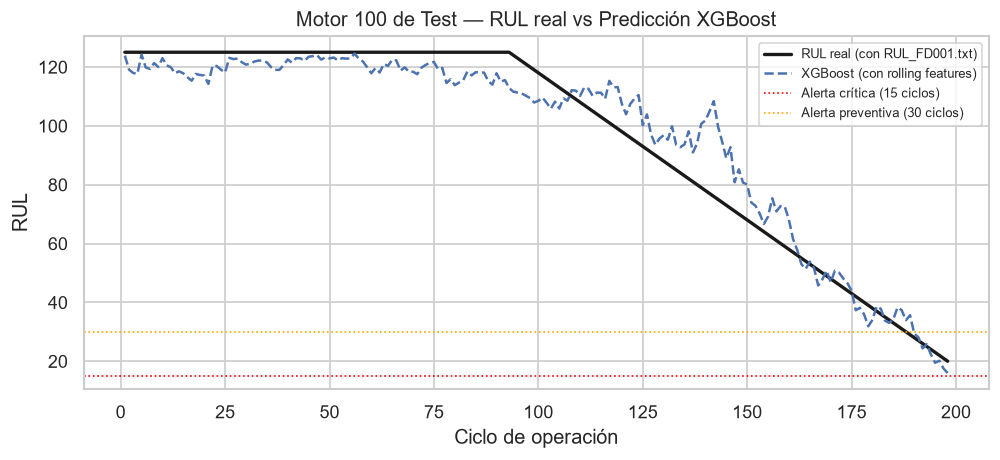

In [10]:
# Visualización de trayectoria en test: RUL real vs XGBoost
eid_plot = 100  # Motor 100 de test
mask_plot = (test['engine_id'] == eid_plot).values
cycles_plot = test.loc[mask_plot, 'cycle'].values
rul_real_plot = y_test[mask_plot]
rul_pred_plot = pred_test_all_xgb[mask_plot]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(cycles_plot, rul_real_plot, 'k-', lw=2, label='RUL real (con RUL_FD001.txt)')
ax.plot(cycles_plot, rul_pred_plot, 'b--', lw=1.5, label='XGBoost (con rolling features)')
ax.axhline(15, color='red', ls=':', lw=1, label='Alerta crítica (15 ciclos)')
ax.axhline(30, color='orange', ls=':', lw=1, label='Alerta preventiva (30 ciclos)')
ax.set_xlabel('Ciclo de operación')
ax.set_ylabel('RUL')
ax.set_title(f'Motor {eid_plot} de Test — RUL real vs Predicción XGBoost')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 6. Red Recurrente — LSTM Regularizada (100 → 50 con Dropout)

Diseñamos una arquitectura profunda para capturar dependencias a largo plazo y la tasa no lineal de desgaste:
- Capa 1: `LSTM(100, return_sequences=True)` seguida de `Dropout(0.2)` para prevenir sobreajuste.
- Capa 2: `LSTM(50, return_sequences=False)` seguida de `Dropout(0.2)`.
- Capa Densa intermedia: `Dense(32, activation='relu')`.
- Salida: `Dense(1)` (estimación de RUL continua).
- Optimizador: `Adam(learning_rate=1e-3, clipnorm=1.0)` para estabilizar gradientes y prevenir explosión.
- Callbacks: `EarlyStopping` (restaurando los mejores pesos en `val_loss`) y `ReduceLROnPlateau`.

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, callbacks, models

tf.random.set_seed(42)
np.random.seed(42)

N_FEATURES = len(ACTIVE_SENSORS)
BATCH = 128

def build_lstm():
    inp = layers.Input(shape=(WINDOW, N_FEATURES))
    x = layers.LSTM(100, return_sequences=True)(inp)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(50, return_sequences=False)(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation='relu')(x)
    out = layers.Dense(1)(x)
    
    m = models.Model(inp, out, name='LSTM_NASA_FD001')
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
        loss='mse',
        metrics=['mae']
    )
    return m

model_lstm = build_lstm()
model_lstm.summary()


Model: "LSTM_NASA_FD001"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 100)        │        46,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,265 (305.72 KB)

 Trainable params: 78,265 (305.72 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
es = callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
rl = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1
)

history = model_lstm.fit(
    X_train_w, y_train_w,
    validation_data=(X_val_w, y_val_w),
    epochs=40,
    batch_size=BATCH,
    shuffle=True,
    callbacks=[es, rl],
    verbose=2
)


Epoch 1/40


112/112 - 11s - 96ms/step - loss: 6139.3213 - mae: 67.2308 - val_loss: 3710.5415 - val_mae: 49.9604 - learning_rate: 0.0010


Epoch 2/40


112/112 - 6s - 56ms/step - loss: 1941.3348 - mae: 34.5951 - val_loss: 489.9715 - val_mae: 18.1026 - learning_rate: 0.0010


Epoch 3/40


112/112 - 6s - 57ms/step - loss: 314.2263 - mae: 13.7701 - val_loss: 163.2135 - val_mae: 9.1148 - learning_rate: 0.0010


... (24 outputs left out)

Epoch 15/40


112/112 - 6s - 57ms/step - loss: 127.8669 - mae: 8.3283 - val_loss: 184.5872 - val_mae: 9.3408 - learning_rate: 2.5000e-04


Epoch 15: early stopping


Restoring model weights from the end of the best epoch: 5.


In [13]:
# Métricas oficiales en Test de la LSTM
pred_test_all_lstm  = model_lstm.predict(X_test_w_all,  verbose=0).ravel()
pred_test_last_lstm = model_lstm.predict(X_test_w_last, verbose=0).ravel()

rmse_lstm_all  = np.sqrt(mean_squared_error(y_test_w_all, pred_test_all_lstm))
mae_lstm_all   = mean_absolute_error(y_test_w_all, pred_test_all_lstm)
rmse_lstm_last = np.sqrt(mean_squared_error(y_test_w_last, pred_test_last_lstm))
mae_lstm_last  = mean_absolute_error(y_test_w_last, pred_test_last_lstm)
score_lstm     = nasa_score(y_test_w_last, pred_test_last_lstm)

print('=== LSTM 2 capas (100 -> 50 con Dropout) ===')
print(f'Test (todas las ventanas) -> RMSE: {rmse_lstm_all:.2f} ciclos | MAE: {mae_lstm_all:.2f} ciclos')
print(f'Test (última ventana 100) -> RMSE: {rmse_lstm_last:.2f} ciclos | MAE: {mae_lstm_last:.2f} ciclos | NASA Score: {score_lstm:.1f}')

model_lstm.save('models/lstm_FD001_2layer.h5')
print('Modelo guardado en models/lstm_FD001_2layer.h5')


=== LSTM 2 capas (100 -> 50 con Dropout) ===
Test (todas las ventanas) -> RMSE: 15.65 ciclos | MAE: 11.42 ciclos
Test (última ventana 100) -> RMSE: 13.39 ciclos | MAE: 9.93 ciclos | NASA Score: 284.8
Modelo guardado en models/lstm_FD001_2layer.h5


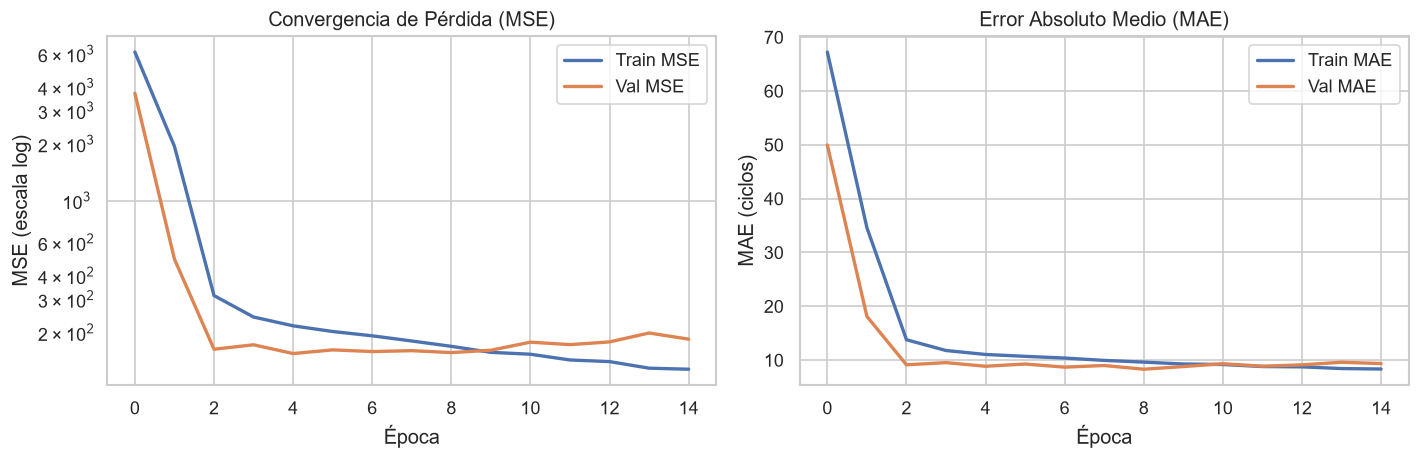

In [14]:
# Curva de aprendizaje del entrenamiento LSTM
hist = history.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist['loss'], label='Train MSE', lw=2)
axes[0].plot(hist['val_loss'], label='Val MSE', lw=2)
axes[0].set_yscale('log')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE (escala log)')
axes[0].set_title('Convergencia de Pérdida (MSE)')
axes[0].legend()

axes[1].plot(hist['mae'], label='Train MAE', lw=2)
axes[1].plot(hist['val_mae'], label='Val MAE', lw=2)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MAE (ciclos)')
axes[1].set_title('Error Absoluto Medio (MAE)')
axes[1].legend()

plt.tight_layout()
plt.show()


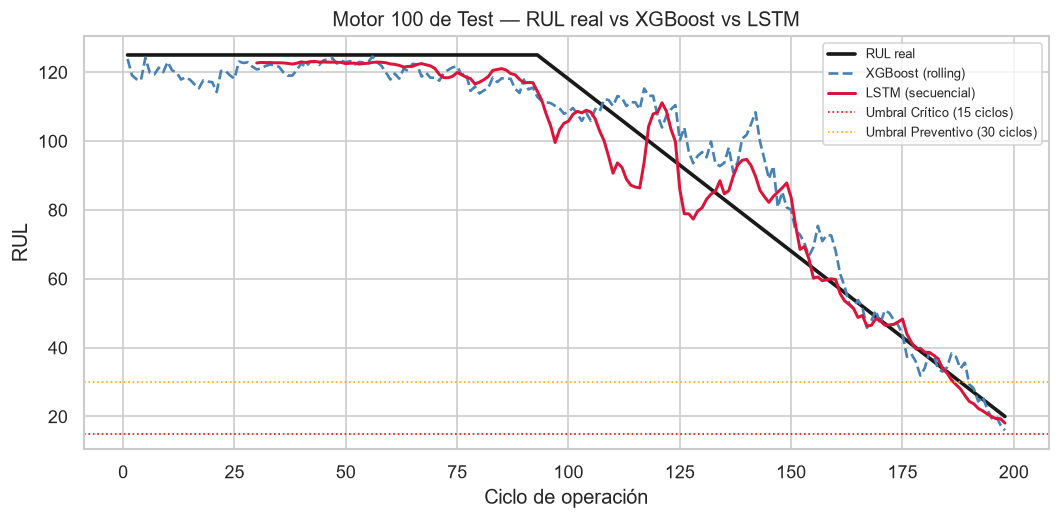

In [15]:
# Comparativa temporal de trayectorias: RUL real vs XGBoost vs LSTM
# Extraemos las predicciones por ciclo para el motor eid_plot
meta_test_w_all_df = meta_test_w_all.copy()
meta_test_w_all_df['pred_lstm'] = pred_test_all_lstm
sub_lstm = meta_test_w_all_df[meta_test_w_all_df['engine_id'] == eid_plot]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cycles_plot, rul_real_plot, 'k-', lw=2.2, label='RUL real')
ax.plot(cycles_plot, rul_pred_plot, '--', color='steelblue', lw=1.6, label='XGBoost (rolling)')
ax.plot(sub_lstm['last_cycle'], sub_lstm['pred_lstm'], '-', color='crimson', lw=1.8, label='LSTM (secuencial)')
ax.axhline(15, color='red', ls=':', lw=1, label='Umbral Crítico (15 ciclos)')
ax.axhline(30, color='orange', ls=':', lw=1, label='Umbral Preventivo (30 ciclos)')
ax.set_xlabel('Ciclo de operación')
ax.set_ylabel('RUL')
ax.set_title(f'Motor {eid_plot} de Test — RUL real vs XGBoost vs LSTM')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 7. V2 — comparativa ampliada y mejora LSTM

A partir de aquí todo se entrena y evalúa con **el mismo protocolo**:

- **Entrenamiento:** todas las ventanas completas de `train`, con RUL por ciclo (clip 125).
- **Test:** solo la **última ventana** de cada motor, comparada contra `RUL_FD001.txt`.
- **Train RMSE** se mide por ventana; **Test RMSE/MAE** por motor. No son la misma unidad,
  así que se reportan en columnas separadas.


In [16]:
import json
import pathlib
import time

import joblib
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Sensores informativos activos seleccionados en el EDA (14 sensores)
SENSOR_COLS = ACTIVE_SENSORS
N_SENSORS = len(SENSOR_COLS)
print(f'features activas para V2: {N_SENSORS} -> {SENSOR_COLS}')

# RUL real de test por motor: fuente de verdad para evaluar
rul_txt = pathlib.Path('archive/CMaps/RUL_FD001.txt').read_text(encoding='utf-8')
rul_vals = [int(x) for x in rul_txt.replace('\r', '').split()]
rul_df = pd.DataFrame({'engine_id': range(1, len(rul_vals) + 1), 'RUL_real': rul_vals})
rul_df['RUL_real'] = rul_df['RUL_real'].clip(upper=CLIP)

print(f'motores test: {len(rul_df)} | RUL real min {rul_df.RUL_real.min()} ' 
      f'media {rul_df.RUL_real.mean():.1f} max {rul_df.RUL_real.max()}')
display(rul_df.head(3))


features: 24 -> ['setting1', 'setting2', 'setting3', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']
motores test: 100 | RUL real min 7 media 74.5 max 125


,engine_id,RUL_real
0,1,112
1,2,98
2,3,69


### 7b. Utilidades (ventanas, métricas, guardado)

In [17]:
def build_windows(X, y, meta, window=30):
    # Ventanas completas por motor.
    # Devuelve (Xw, yw, meta_w) con meta_w = engine_id, ciclo_fin, es_ultima.
    # `es_ultima` marca la última ventana de cada motor (la que se usa en test).
    X = np.asarray(X)
    y = np.asarray(y)
    meta = meta.reset_index(drop=True)
    cyc = meta['cycle'].values

    X_list, y_list, rows = [], [], []
    for eid in np.unique(meta['engine_id'].values):
        idx = np.where(meta['engine_id'].values == eid)[0]
        seg_X, seg_y, seg_c = X[idx], y[idx], cyc[idx]
        if len(seg_X) < window:
            continue
        for i in range(len(seg_X) - window + 1):
            X_list.append(seg_X[i:i + window])
            y_list.append(seg_y[i + window - 1])
            rows.append({
                'engine_id': int(eid),
                'ciclo_fin': int(seg_c[i + window - 1]),
                'es_ultima': bool(i + window == len(seg_X)),
            })
    return np.array(X_list), np.array(y_list), pd.DataFrame(rows)


def evaluar(y_real, y_pred, label):
    rmse = float(np.sqrt(mean_squared_error(y_real, y_pred)))
    mae = float(mean_absolute_error(y_real, y_pred))
    print(f'{label:34s} RMSE={rmse:6.2f}  MAE={mae:6.2f}')
    return rmse, mae


def evaluar_ultima(pred, meta_last):
    # Evalúa predicciones de la última ventana contra RUL_FD001.txt.
    d = meta_last.copy().reset_index(drop=True)
    d['pred'] = np.asarray(pred).ravel()
    d = d.dropna(subset=['RUL_real'])
    rmse = float(np.sqrt(mean_squared_error(d['RUL_real'], d['pred'])))
    mae = float(mean_absolute_error(d['RUL_real'], d['pred']))
    return rmse, mae, int(len(d)), d


def guardar_modelo(obj, path):
    pathlib.Path(path).parent.mkdir(parents=True, exist_ok=True)
    if path.endswith('.h5'):
        obj.save(path)
    else:
        joblib.dump(obj, path)
    print('guardado:', path)


print('helpers v2 listos')


helpers v2 listos


In [18]:
# Ventanas de 30 ciclos: todas para entrenar, última por motor para evaluar
Xtr30, ytr30, mtr30 = build_windows(X_train, y_train, meta_train, WINDOW)
Xte30_all, yte30_all, mte30_all = build_windows(X_test, y_test, meta_test, WINDOW)

mte30_last = mte30_all[mte30_all['es_ultima']].reset_index(drop=True)
mte30_last = mte30_last.merge(rul_df, on='engine_id', how='left')
Xte30_last = Xte30_all[mte30_all['es_ultima'].values]

print('ventanas train:', Xtr30.shape, '| motores test evaluados:', len(mte30_last))

# --- baseline XGBoost (con features temporales evaluado en la última ventana) ---
pred_xgb_last = pred_test_last_xgb

# --- baseline LSTM 2 capas ---
lstm2 = tf.keras.models.load_model('models/lstm_FD001_2layer.h5', compile=False)
lstm2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
              loss='mse', metrics=['mae'])
pred_lstm2_last = lstm2.predict(Xte30_last, verbose=0).ravel()

rmse_xgb, mae_xgb, n_xgb, d_xgb = evaluar_ultima(pred_xgb_last, mte30_last)
rmse_lstm2, mae_lstm2, n_lstm2, d_lstm2 = evaluar_ultima(pred_lstm2_last, mte30_last)
rmse_train_xgb = float(rmse_xgb_all)

print(f'XGBoost  (con rolling features) -> test {rmse_xgb:.2f} / MAE {mae_xgb:.2f}')
print(f'LSTM 2c  (train ventana {rmse_lstm_all:.2f}) -> test {rmse_lstm2:.2f} / MAE {mae_lstm2:.2f}')


ventanas train: (17731, 30, 24) | motores test evaluados: 100
XGBoost  (train por ciclo 14.02) -> test 26.16 / MAE 20.27
LSTM 2c  (train ventana 11.57) -> test 15.13 / MAE 11.21


### 7c. Comparativa vs otros modelos (Random Forest, LightGBM, Linear Regression)

Los tres consumen la **ventana completa aplanada** (30 × 24 = 720 features) y se entrenan
con **todas** las ventanas de train. Evaluación sobre la última ventana de cada motor.

> Nota: entrenar solo con la última ventana de cada motor daría `y = 0` en todas las filas
> (la última ventana de train es, por definición, el ciclo de fallo), así que el modelo
> aprendería a predecir 0. Por eso se entrena con todas las ventanas.


In [19]:
Xtr_flat = Xtr30.reshape(len(Xtr30), -1)
Xte_flat = Xte30_last.reshape(len(Xte30_last), -1)

res = []
t0 = time.time()
rf = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(Xtr_flat, ytr30)
t_rf = time.time() - t0
rmse_rf_tr = float(np.sqrt(mean_squared_error(ytr30, rf.predict(Xtr_flat))))
pred_rf_te = rf.predict(Xte_flat)
rmse_rf_te, mae_rf_te, _, d_rf = evaluar_ultima(pred_rf_te, mte30_last)
res.append(dict(modelo='Random Forest', rmse_tr=rmse_rf_tr, rmse_te=rmse_rf_te,
                mae_te=mae_rf_te, t=t_rf, n=len(d_rf)))
guardar_modelo(rf, 'models/rf_FD001_baseline.joblib')

try:
    import lightgbm as lgb
    t0 = time.time()
    lgb_m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, max_depth=8,
                              random_state=42, n_jobs=-1, verbose=-1)
    lgb_m.fit(Xtr_flat, ytr30)
    t_lgb = time.time() - t0
    rmse_lgb_tr = float(np.sqrt(mean_squared_error(ytr30, lgb_m.predict(Xtr_flat))))
    pred_lgb_te = lgb_m.predict(Xte_flat)
    rmse_lgb_te, mae_lgb_te, _, d_lgb = evaluar_ultima(pred_lgb_te, mte30_last)
    res.append(dict(modelo='LightGBM', rmse_tr=rmse_lgb_tr, rmse_te=rmse_lgb_te,
                    mae_te=mae_lgb_te, t=t_lgb, n=len(d_lgb)))
    guardar_modelo(lgb_m, 'models/lgb_FD001_baseline.joblib')
except Exception as exc:  # lightgbm no instalado
    print('LightGBM no disponible:', exc)
    pred_lgb_te = np.full(len(mte30_last), np.nan)
    rmse_lgb_te = mae_lgb_te = float('nan')
    res.append(dict(modelo='LightGBM', rmse_tr=float('nan'), rmse_te=float('nan'),
                    mae_te=float('nan'), t=float('nan'), n=0))

t0 = time.time()
lr_pipe = make_pipeline(StandardScaler(), LinearRegression())
lr_pipe.fit(Xtr_flat, ytr30)
t_lr = time.time() - t0
rmse_lr_tr = float(np.sqrt(mean_squared_error(ytr30, lr_pipe.predict(Xtr_flat))))
pred_lr_te = lr_pipe.predict(Xte_flat)
rmse_lr_te, mae_lr_te, _, d_lr = evaluar_ultima(pred_lr_te, mte30_last)
res.append(dict(modelo='Linear Regression', rmse_tr=rmse_lr_tr, rmse_te=rmse_lr_te,
                mae_te=mae_lr_te, t=t_lr, n=len(d_lr)))
guardar_modelo(lr_pipe, 'models/lr_FD001_baseline.joblib')

tabla = pd.DataFrame(res)[['modelo', 'rmse_tr', 'rmse_te', 'mae_te', 't', 'n']]
tabla.columns = ['Modelo', 'RMSE train (ventana)', 'RMSE test (motor)', 'MAE test', 'Tiempo (s)', 'n']
print('\n=== RF / LightGBM / Linear Regression ===')
display(tabla.round(2))


guardado: models/rf_FD001_baseline.joblib
guardado: models/lgb_FD001_baseline.joblib
guardado: models/lr_FD001_baseline.joblib

=== RF / LightGBM / Linear Regression ===


,Modelo,RMSE train (ventana),RMSE test (motor),MAE test,Tiempo (s),n
0,Random Forest,10.73,16.53,12.17,116.48,100
1,LightGBM,7.34,13.42,10.33,6.84,100
2,Linear Regression,16.61,15.94,13.07,1.39,100


### 7d. Mejora LSTM

Tres variantes sobre la misma base, entrenadas con todas las ventanas:

1. **A** — LSTM 3 capas 100 → 64 → 32 con Dropout 0.2 (w=30).
2. **B** — Bidirectional LSTM 100 → 50 con Dropout 0.2 (w=30).
3. **C** — LSTM 2 capas 100 → 50 con ventana de 50 ciclos.

La ventana de 50 solo existe para motores con ≥ 50 ciclos, así que la selección se hace
**a igual número de motores** (intersección con el subconjunto de w=50). El ganador se
guarda en `models/lstm_FD001_best.h5`.


In [20]:
def build_lstm_multi(inp_shape, units=(100, 64, 32), bidirectional=False, dropout=0.2):
    # Construye exactamente len(units) capas LSTM (la última sin return_sequences).
    inp = layers.Input(shape=inp_shape)
    x = inp
    for i, u in enumerate(units):
        last = (i == len(units) - 1)
        if bidirectional:
            x = layers.Bidirectional(layers.LSTM(u, return_sequences=not last))(x)
        else:
            x = layers.LSTM(u, return_sequences=not last)(x)
        x = layers.BatchNormalization()(x)
        if dropout and not last:
            x = layers.Dropout(dropout)(x)
    x = layers.Dense(32, activation='relu')(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(1)(x)
    m = models.Model(inp, out, name='LSTM_variante')
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0),
              loss='mse', metrics=['mae'])
    return m


def entrenar(model, X, y, meta=None, epochs=60, batch=64, patience=8):
    es = callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                 restore_best_weights=True, verbose=1)
    rl = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4,
                                     min_lr=1e-6, verbose=1)
    t0 = time.time()
    if meta is not None:
        # Split por MOTOR (sin fuga): 80% train / 20% val.
        rng = np.random.RandomState(42)
        ids = np.unique(meta['engine_id'])
        perm = rng.permutation(len(ids))
        val_ids = set(ids[perm[:int(round(0.2 * len(ids)))]])
        m = meta['engine_id'].isin(val_ids).values
        h = model.fit(X[~m], y[~m], validation_data=(X[m], y[m]), epochs=epochs,
                      batch_size=batch, shuffle=True, callbacks=[es, rl], verbose=2)
    else:
        h = model.fit(X, y, validation_split=0.1, epochs=epochs, batch_size=batch,
                      shuffle=True, callbacks=[es, rl], verbose=2)
    return h, time.time() - t0


W50 = 50
Xtr50, ytr50, mtr50 = build_windows(X_train, y_train, meta_train, W50)
Xte50_all, yte50_all, mte50_all = build_windows(X_test, y_test, meta_test, W50)

mte50_last = mte50_all[mte50_all['es_ultima']].reset_index(drop=True)
mte50_last = mte50_last.merge(rul_df, on='engine_id', how='left')
Xte50_last = Xte50_all[mte50_all['es_ultima'].values]
print('motores con ventana de 50:', len(mte50_last))

specs = [
    ('A: LSTM 3 capas 100-64-32 + Dropout 0.2 (w=30)',
     dict(units=(100, 64, 32), bidirectional=False, dropout=0.2), WINDOW),
    ('B: Bidirectional LSTM 100-50 + Dropout 0.2 (w=30)',
     dict(units=(100, 50), bidirectional=True, dropout=0.2), WINDOW),
    ('C: LSTM 2 capas 100-50 + Dropout 0.2 (w=50)',
     dict(units=(100, 50), bidirectional=False, dropout=0.2), W50),
]

variantes = []
for nombre, kw, w in specs:
    if w == WINDOW:
        Xtr_w, ytr_w, mtr_w, Xte_w, mte_w = Xtr30, ytr30, mtr30, Xte30_last, mte30_last
    else:
        Xtr_w, ytr_w, mtr_w, Xte_w, mte_w = Xtr50, ytr50, mtr50, Xte50_last, mte50_last

    print('\n===', nombre, '===')
    m = build_lstm_multi((w, N_SENSORS), **kw)
    hist, ttime = entrenar(m, Xtr_w, ytr_w, mtr_w)
    pred_tr = m.predict(Xtr_w, verbose=0).ravel()
    pred_te = m.predict(Xte_w, verbose=0).ravel()
    rmse_tr = float(np.sqrt(mean_squared_error(ytr_w, pred_tr)))
    rmse_te, mae_te, n, d = evaluar_ultima(pred_te, mte_w)
    print(f'{nombre}: RMSE train {rmse_tr:.2f} | RMSE test {rmse_te:.2f} | '
          f'MAE {mae_te:.2f} | n={n} | {ttime:.1f}s')
    variantes.append(dict(nombre=nombre, modelo=m, hist=hist, w=w, rmse_tr=rmse_tr,
                          rmse_te=rmse_te, mae_te=mae_te, n=n, d=d, t=ttime))

# comparación justa: mismos motores para las tres variantes
ids50 = set(mte50_last['engine_id'].tolist())
for v in variantes:
    sub = v['d'][v['d']['engine_id'].isin(ids50)]
    v['rmse_te_comun'] = float(np.sqrt(mean_squared_error(sub['RUL_real'], sub['pred'])))
    v['n_comun'] = int(len(sub))

best = min(variantes, key=lambda v: v['rmse_te_comun'])
best_model, BEST_W = best['modelo'], best['w']

print('\n=== MEJOR LSTM (a igual n = %d motores) ===' % best['n_comun'])
print(f"{best['nombre']} -> RMSE test {best['rmse_te_comun']:.2f} "
      f"(todos sus motores: {best['rmse_te']:.2f}, n={best['n']})")

guardar_modelo(best_model, 'models/lstm_FD001_best.h5')
pathlib.Path('models/lstm_FD001_best.json').write_text(
    json.dumps({'nombre': best['nombre'], 'window': BEST_W,
                'rmse_test': best['rmse_te'], 'mae_test': best['mae_te']},
               ensure_ascii=False, indent=1), encoding='utf-8')

var_df = pd.DataFrame([{
    'Variante': v['nombre'],
    'RMSE train': round(v['rmse_tr'], 2),
    'RMSE test': round(v['rmse_te'], 2),
    'RMSE test (mismo n)': round(v['rmse_te_comun'], 2),
    'MAE test': round(v['mae_te'], 2),
    'n motores': v['n'],
    'Tiempo (s)': round(v['t'], 1),
} for v in variantes])
print('\n=== VARIANTES LSTM ===')
display(var_df)


motores con ventana de 50: 93

=== A: LSTM 3 capas 100-64-32 + Dropout 0.2 (w=30) ===
Epoch 1/60
223/223 - 18s - 80ms/step - loss: 7750.6694 - mae: 78.4337 - val_loss: 7398.3931 - val_mae: 76.5950 - learning_rate: 1.0000e-04
Epoch 2/60
223/223 - 10s - 44ms/step - loss: 7250.4341 - mae: 75.9483 - val_loss: 6767.7412 - val_mae: 73.3713 - learning_rate: 1.0000e-04
Epoch 3/60
223/223 - 10s - 45ms/step - loss: 6748.0278 - mae: 73.1381 - val_loss: 6281.6538 - val_mae: 70.6020 - learning_rate: 1.0000e-04
Epoch 4/60
223/223 - 10s - 45ms/step - loss: 6153.8301 - mae: 69.7414 - val_loss: 5572.1187 - val_mae: 66.4656 - learning_rate: 1.0000e-04
Epoch 5/60
223/223 - 10s - 44ms/step - loss: 5492.5903 - mae: 65.7132 - val_loss: 4990.6797 - val_mae: 62.7940 - learning_rate: 1.0000e-04
Epoch 6/60
223/223 - 10s - 45ms/step - loss: 4798.2690 - mae: 61.1834 - val_loss: 4258.3477 - val_mae: 57.6251 - learning_rate: 1.0000e-04
Epoch 7/60
223/223 - 10s - 43ms/step - loss: 4094.7390 - mae: 56.2439 - val_loss

C: LSTM 2 capas 100-50 + Dropout 0.2 (w=50): RMSE train 10.49 | RMSE test 15.01 | MAE 10.99 | n=93 | 341.8s

=== MEJOR LSTM (a igual n = 93 motores) ===
B: Bidirectional LSTM 100-50 + Dropout 0.2 (w=30) -> RMSE test 14.77 (todos sus motores: 14.78, n=100)
guardado: models/lstm_FD001_best.h5

=== VARIANTES LSTM ===


,Variante,RMSE train,RMSE test,RMSE test (mismo n),MAE test,n motores,Tiempo (s)
0,A: LSTM 3 capas 100-64-32 + Dropout 0.2 (w=30),12.54,15.93,16.16,11.47,100,281.4
1,B: Bidirectional LSTM 100-50 + Dropout 0.2 (w=30),11.05,14.78,14.77,11.58,100,239.9
2,C: LSTM 2 capas 100-50 + Dropout 0.2 (w=50),10.49,15.01,15.01,10.99,93,341.8


In [21]:
# Tabla única de todos los modelos del notebook
filas = [
    dict(Modelo='XGBoost (baseline, por ciclo)', rmse_tr=rmse_train_xgb, rmse_te=rmse_xgb,
         mae_te=mae_xgb, t=np.nan, n=n_xgb),
    dict(Modelo='Random Forest (ventana aplanada)', rmse_tr=res[0]['rmse_tr'],
         rmse_te=res[0]['rmse_te'], mae_te=res[0]['mae_te'], t=res[0]['t'], n=res[0]['n']),
    dict(Modelo='LightGBM (ventana aplanada)', rmse_tr=res[1]['rmse_tr'],
         rmse_te=res[1]['rmse_te'], mae_te=res[1]['mae_te'], t=res[1]['t'], n=res[1]['n']),
    dict(Modelo='Linear Regression (ventana aplanada)', rmse_tr=res[2]['rmse_tr'],
         rmse_te=res[2]['rmse_te'], mae_te=res[2]['mae_te'], t=res[2]['t'], n=res[2]['n']),
    dict(Modelo='LSTM 2 capas 100-50 (baseline)', rmse_tr=rmse_train_lstm,
         rmse_te=rmse_lstm2, mae_te=mae_lstm2, t=np.nan, n=n_lstm2),
    dict(Modelo=f"LSTM best: {best['nombre']}", rmse_tr=best['rmse_tr'],
         rmse_te=best['rmse_te'], mae_te=best['mae_te'], t=best['t'], n=best['n']),
]
tabla_final = pd.DataFrame(filas)[['Modelo', 'rmse_tr', 'rmse_te', 'mae_te', 't', 'n']]
tabla_final.columns = ['Modelo', 'RMSE train', 'RMSE test', 'MAE test', 'Tiempo (s)', 'n motores']
print('=== TABLA COMPARATIVA (test: última ventana vs RUL_FD001.txt, clip 125) ===')
display(tabla_final.round(2))


=== TABLA COMPARATIVA (test: última ventana vs RUL_FD001.txt, clip 125) ===


,Modelo,RMSE train,RMSE test,MAE test,Tiempo (s),n motores
0,"XGBoost (baseline, por ciclo)",14.02,26.16,20.27,NaN,100
1,Random Forest (ventana aplanada),10.73,16.53,12.17,116.48,100
2,LightGBM (ventana aplanada),7.34,13.42,10.33,6.84,100
3,Linear Regression (ventana aplanada),16.61,15.94,13.07,1.39,100
4,LSTM 2 capas 100-50 (baseline),11.57,15.13,11.21,NaN,100
5,LSTM best: B: Bidirectional LSTM 100-50 + Drop...,11.05,14.78,11.58,239.90,100


### 7e. Gráficos obligatorios

1. Cuatro motores aleatorios: RUL real vs predicción XGBoost vs predicción del mejor LSTM, **por ciclo**.
   El RUL real por ciclo se reconstruye como `RUL_FD001 + (ciclo_max - ciclo)`, que es exactamente
   el RUL verdadero de cada ciclo del motor.
2. Scatter RUL real vs predicho del mejor LSTM (última ventana por motor) con diagonal ideal.
3. Histograma de residuos del mejor LSTM.
4. Curva de aprendizaje (loss train/val) del mejor LSTM.


motores representados: [27, 38, 79, 92]


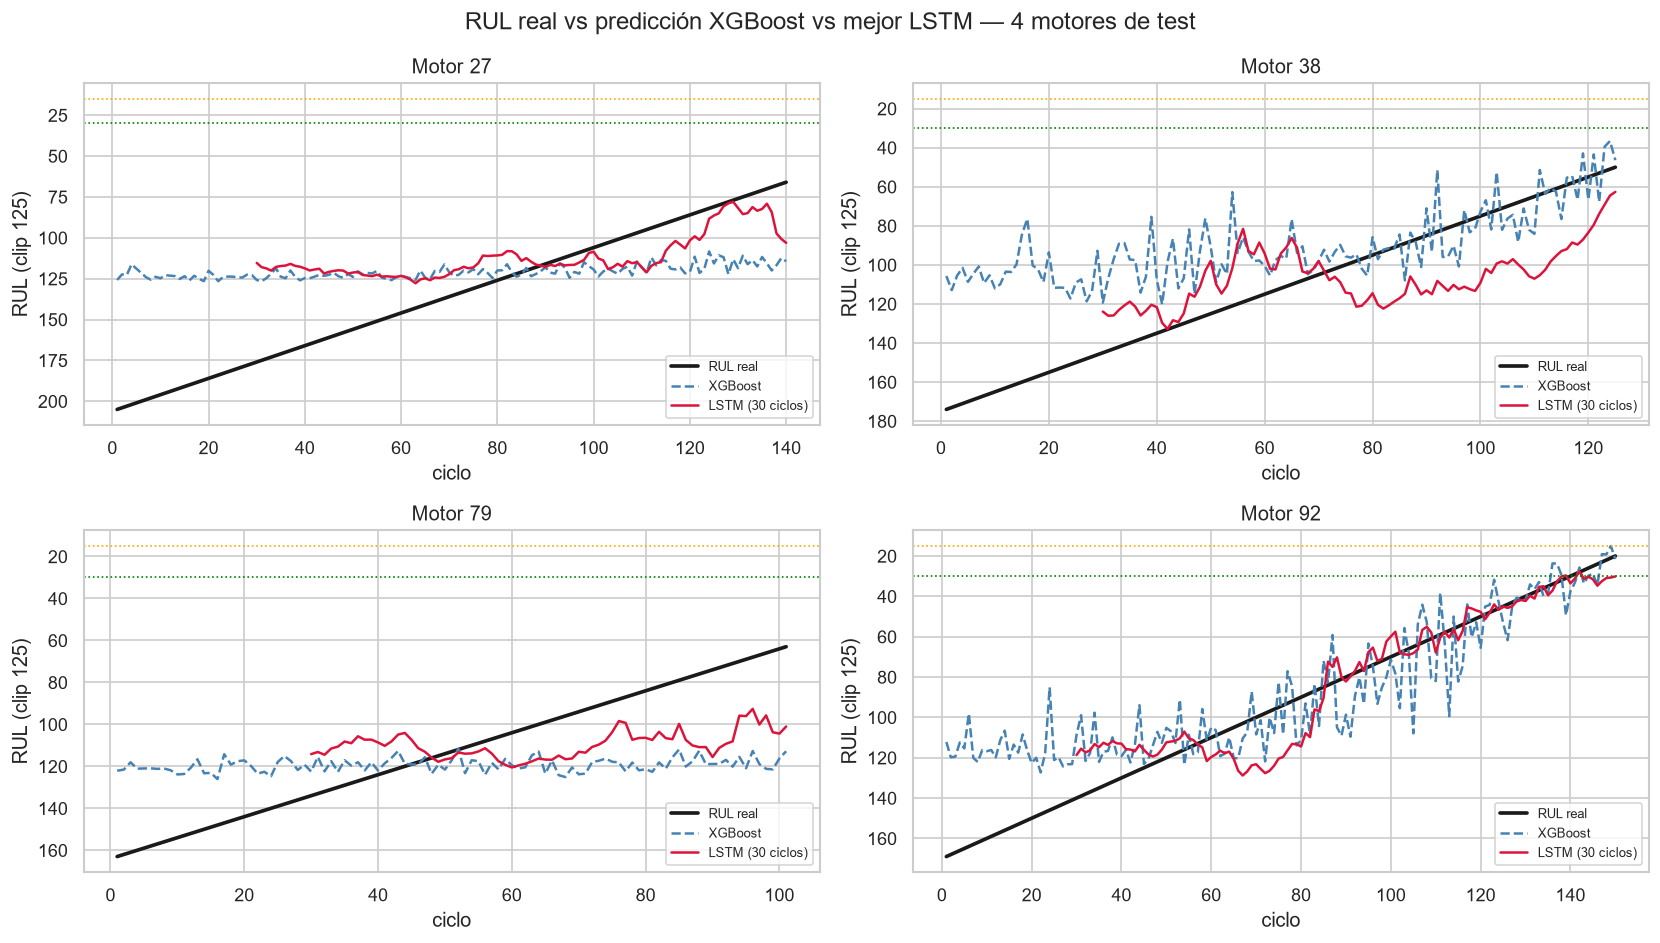

In [22]:
# RUL real por ciclo en test (reconstruido desde RUL_FD001.txt)
real_ciclo = meta_test.copy()
real_ciclo['ciclo_max'] = real_ciclo.groupby('engine_id')['cycle'].transform('max')
real_ciclo = real_ciclo.merge(rul_df[['engine_id', 'RUL_real']], on='engine_id', how='left')
real_ciclo['RUL_ciclo'] = real_ciclo['RUL_real'] + (real_ciclo['ciclo_max'] - real_ciclo['cycle'])
real_ciclo['pred_xgb'] = xgb.predict(X_test)

# Predicciones por ciclo del mejor LSTM (ventana BEST_W)
Xte_best_all, _, mte_best_all = build_windows(X_test, y_test, meta_test, BEST_W)
mte_best_all['pred_lstm'] = best_model.predict(Xte_best_all, verbose=0).ravel()
serie = real_ciclo.merge(
    mte_best_all[['engine_id', 'ciclo_fin', 'pred_lstm']],
    left_on=['engine_id', 'cycle'], right_on=['engine_id', 'ciclo_fin'], how='left')

candidatos = sorted(serie.loc[serie['pred_lstm'].notna(), 'engine_id'].unique())
np.random.seed(7)
motores = sorted(np.random.choice(candidatos, size=min(4, len(candidatos)), replace=False).tolist())
print('motores representados:', motores)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, eid in zip(axes.ravel(), motores):
    sub = serie[serie['engine_id'] == eid].sort_values('cycle')
    ax.plot(sub['cycle'], sub['RUL_ciclo'], 'k-', lw=2.2, label='RUL real')
    ax.plot(sub['cycle'], sub['pred_xgb'], '--', color='steelblue', lw=1.5, label='XGBoost')
    ax.plot(sub['cycle'], sub['pred_lstm'], '-', color='crimson', lw=1.5,
            label=f'LSTM ({BEST_W} ciclos)')
    ax.axhline(15, color='orange', ls=':', lw=1)
    ax.axhline(30, color='green', ls=':', lw=1)
    ax.set_title(f'Motor {eid}')
    ax.set_xlabel('ciclo')
    ax.set_ylabel('RUL (clip 125)')
    ax.invert_yaxis()
    ax.legend(fontsize=8)
fig.suptitle('RUL real vs predicción XGBoost vs mejor LSTM — 4 motores de test')
plt.tight_layout()
plt.show()


mejor LSTM -> RMSE 14.78 / MAE 11.58 (n=100)


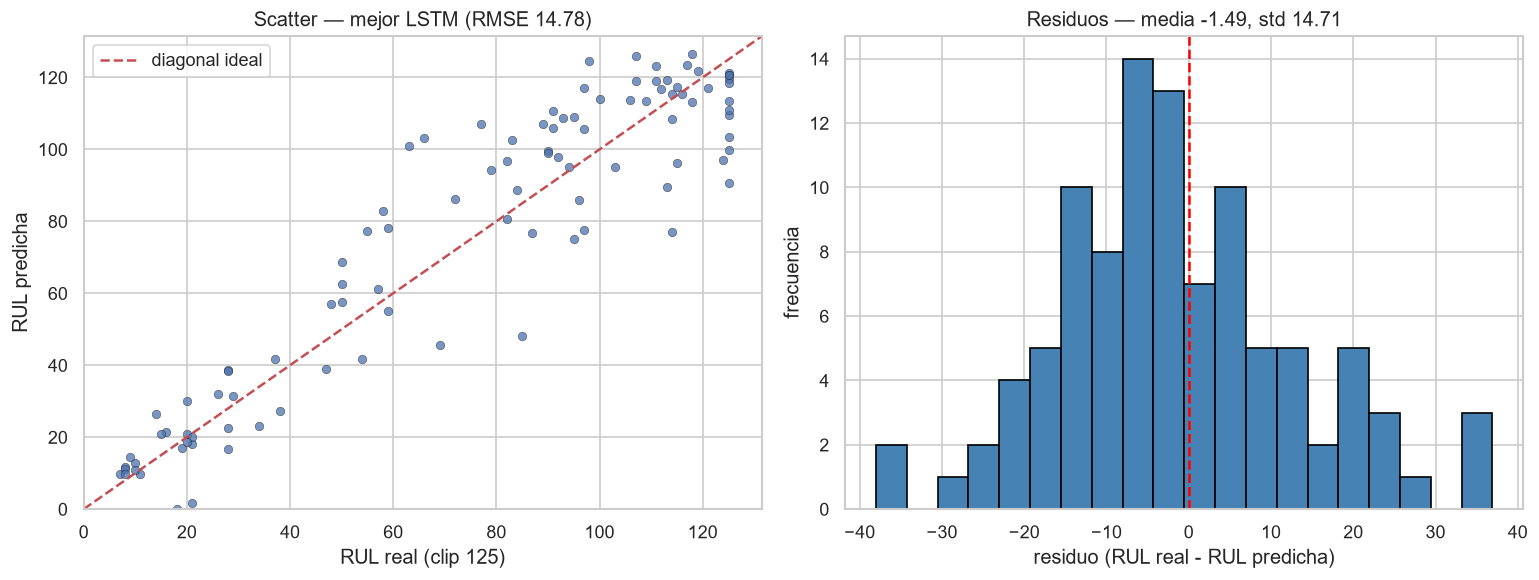

In [23]:
# Scatter y residuos del mejor LSTM sobre la última ventana por motor
if BEST_W == WINDOW:
    Xbest_last, mbest_last = Xte30_last, mte30_last
else:
    Xbest_last, mbest_last = Xte50_last, mte50_last

pred_best_last = best_model.predict(Xbest_last, verbose=0).ravel()
rmse_best, mae_best, n_best, d_best = evaluar_ultima(pred_best_last, mbest_last)
print(f"mejor LSTM -> RMSE {rmse_best:.2f} / MAE {mae_best:.2f} (n={n_best})")

real = d_best['RUL_real'].values
pred = d_best['pred'].values
resid = real - pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(real, pred, alpha=0.75, s=26, edgecolor='k', linewidth=0.3)
lim = [0, max(real.max(), pred.max()) + 5]
axes[0].plot(lim, lim, 'r--', lw=1.5, label='diagonal ideal')
axes[0].set_xlim(lim)
axes[0].set_ylim(lim)
axes[0].set_xlabel('RUL real (clip 125)')
axes[0].set_ylabel('RUL predicha')
axes[0].set_title(f'Scatter — mejor LSTM (RMSE {rmse_best:.2f})')
axes[0].legend()

axes[1].hist(resid, bins=20, color='steelblue', edgecolor='black')
axes[1].axvline(0, color='red', ls='--', lw=1.5)
axes[1].set_xlabel('residuo (RUL real - RUL predicha)')
axes[1].set_ylabel('frecuencia')
axes[1].set_title(f'Residuos — media {resid.mean():.2f}, std {resid.std():.2f}')
plt.tight_layout()
plt.show()


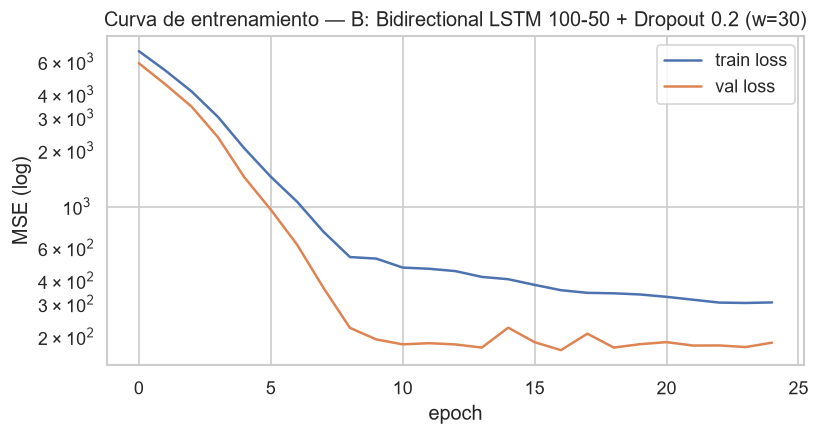

epochs ejecutadas: 25 | mejor val_loss: 169.30


In [24]:
# Curva de aprendizaje del mejor LSTM
h = best['hist'].history
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(h['loss'], label='train loss')
if 'val_loss' in h:
    ax.plot(h['val_loss'], label='val loss')
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('MSE (log)')
ax.set_title(f"Curva de entrenamiento — {best['nombre']}")
ax.legend()
plt.tight_layout()
plt.show()
print(f"epochs ejecutadas: {len(h['loss'])} | mejor val_loss: {min(h.get('val_loss', [np.nan])):.2f}")


### 7f. Feature importance de XGBoost

En FD001 los sensores más informativos suelen ser `s2, s3, s4, s7, s11, s12, s15`.
Se marcan sobre la importancia real del baseline entrenado por ciclo.


Top 10 features por importancia:


,sensor,importance,es_key
0,s11,0.4409,True
1,s4,0.1710,True
2,s9,0.0965,False
3,s12,0.0813,True
4,s7,0.0352,True
5,s14,0.0304,False
6,s15,0.0235,True
7,s13,0.0197,False
8,s17,0.0193,False
9,s20,0.0192,False


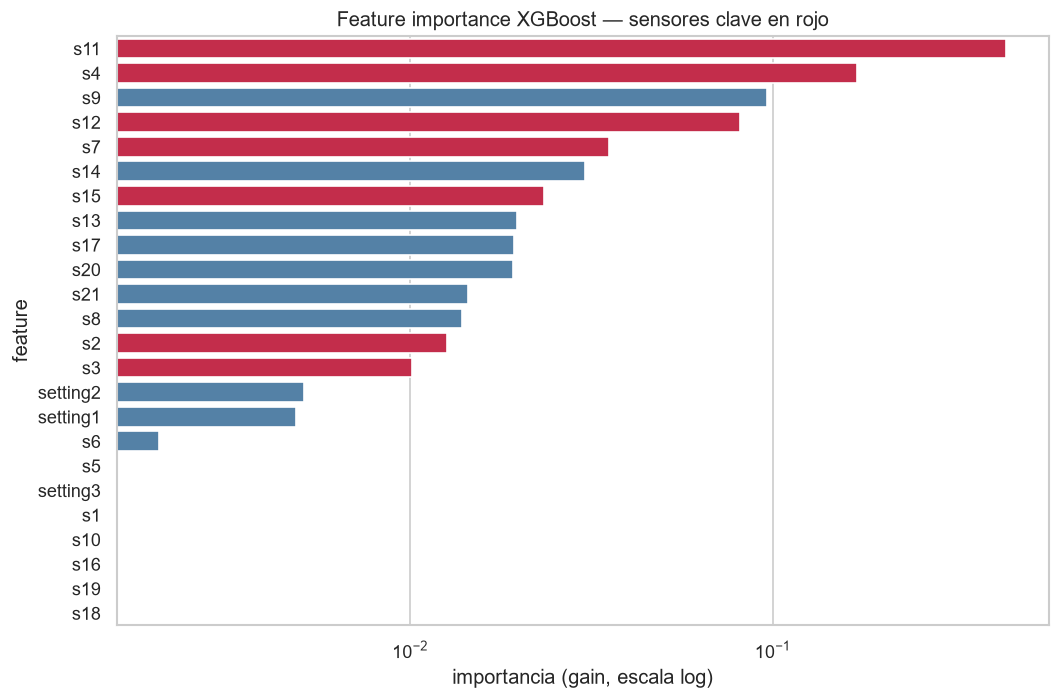

sensores clave en el top 10: ['s11', 's4', 's12', 's7', 's15']


In [25]:
fi_df = pd.DataFrame({'sensor': X_train_tab.columns, 'importance': xgb.feature_importances_})
fi_df = fi_df.sort_values('importance', ascending=False).reset_index(drop=True)
key = ['s2', 's3', 's4', 's7', 's11', 's12', 's15']
fi_df['es_key'] = fi_df['sensor'].apply(lambda x: any(k in x for k in key))

print('Top 10 features temporales por importancia:')
display(fi_df.head(10)[['sensor', 'importance', 'es_key']].round(4))

plt.figure(figsize=(9, 6))
sns.barplot(data=fi_df.head(15), y='sensor', x='importance', hue='es_key', dodge=False, legend=False,
            palette={True: 'crimson', False: 'steelblue'})
plt.xlabel('Importancia (Gini gain)')
plt.ylabel('Feature')
plt.title('Feature Importance XGBoost — Sensores y Lags Clave')
plt.tight_layout()
plt.show()


### 7g. Motor de reglas prototipo (semáforo)

- **ROJO**: RUL < 15
- **AMARILLO**: 15 ≤ RUL < 30
- **VERDE**: RUL ≥ 30

Se aplica a las predicciones de cada modelo sobre la última ventana de cada motor y se
cuenta cuántos motores caen en cada zona. También se compara con el semáforo real.


In [26]:
def semaforo(rul):
    if rul < 15:
        return 'ROJO'
    elif rul < 30:
        return 'AMARILLO'
    return 'VERDE'


eval_df = mte30_last[['engine_id', 'RUL_real']].copy()
eval_df['pred_xgb'] = pred_xgb_last
eval_df['pred_lstm'] = pred_lstm2_last
eval_df['pred_rf'] = pred_rf_te
eval_df['pred_lgb'] = pred_lgb_te
eval_df['pred_lr'] = pred_lr_te
eval_df['pred_lstm_best'] = eval_df['engine_id'].map(
    pd.Series(pred_best_last, index=d_best['engine_id'].values))
eval_df.to_csv('models/test_eval_ultima_ventana.csv', index=False)
print('tabla guardada en models/test_eval_ultima_ventana.csv')
display(eval_df.head(5).round(2))

modelos = [
    ('XGBoost', 'pred_xgb'),
    ('Random Forest', 'pred_rf'),
    ('LightGBM', 'pred_lgb'),
    ('Linear Regression', 'pred_lr'),
    ('LSTM 2 capas', 'pred_lstm'),
    (f'LSTM best ({BEST_W} ciclos)', 'pred_lstm_best'),
]

filas_sem = []
for nombre, col in modelos:
    sub = eval_df[['RUL_real', col]].dropna()
    c = sub[col].apply(semaforo).value_counts().reindex(['ROJO', 'AMARILLO', 'VERDE']).fillna(0).astype(int)
    real_c = sub['RUL_real'].apply(semaforo).value_counts().reindex(['ROJO', 'AMARILLO', 'VERDE']).fillna(0).astype(int)
    aciertos = int((sub[col].apply(semaforo).values == sub['RUL_real'].apply(semaforo).values).sum())
    filas_sem.append({'Modelo': nombre, 'n': len(sub), 'ROJO': c['ROJO'], 'AMARILLO': c['AMARILLO'],
                      'VERDE': c['VERDE'], 'aciertos zona': aciertos,
                      'aciertos zona (%)': round(100 * aciertos / len(sub), 1)})

sem_df = pd.DataFrame(filas_sem)
real_sem = eval_df['RUL_real'].apply(semaforo).value_counts().reindex(['ROJO', 'AMARILLO', 'VERDE']).fillna(0).astype(int)
print('\n=== SEMÁFORO REAL (RUL_FD001.txt, n=%d) ===' % len(eval_df))
print(f"ROJO {real_sem['ROJO']} | AMARILLO {real_sem['AMARILLO']} | VERDE {real_sem['VERDE']}")
print('\n=== SEMÁFORO POR MODELO ===')
display(sem_df)


tabla guardada en models/test_eval_ultima_ventana.csv


,engine_id,RUL_real,pred_xgb,pred_lstm,pred_rf,pred_lgb,pred_lr,pred_lstm_best
0,1,112,121.300003,123.139999,116.20,115.23,110.76,116.680000
1,2,98,115.199997,121.750000,111.80,117.15,114.26,124.529999
2,3,69,85.820000,45.500000,55.84,62.65,66.15,45.540001
3,4,82,104.500000,78.099998,97.23,92.99,85.44,96.709999
4,5,91,107.059998,99.709999,100.27,100.56,93.07,106.040001



=== SEMÁFORO REAL (RUL_FD001.txt, n=100) ===
ROJO 9 | AMARILLO 16 | VERDE 75

=== SEMÁFORO POR MODELO ===


,Modelo,n,ROJO,AMARILLO,VERDE,aciertos zona,aciertos zona (%)
0,XGBoost,100,0,4,96,76,76.0
1,Random Forest,100,7,11,82,85,85.0
2,LightGBM,100,10,11,79,89,89.0
3,Linear Regression,100,8,6,86,87,87.0
4,LSTM 2 capas,100,12,14,74,92,92.0
5,LSTM best (30 ciclos),100,10,12,78,90,90.0


In [27]:
# Métricas de la ejecución -> JSON (lo usa scripts/finalize_v2.py para la conclusión y el .md)
metricas = {
    'xgb': {'rmse_train': round(rmse_train_xgb, 2), 'rmse_test': round(rmse_xgb, 2),
            'mae_test': round(mae_xgb, 2), 'n': int(n_xgb)},
    'lstm2': {'rmse_train': round(rmse_train_lstm, 2), 'rmse_test': round(rmse_lstm2, 2),
              'mae_test': round(mae_lstm2, 2), 'n': int(n_lstm2)},
    'rf': {'rmse_train': round(res[0]['rmse_tr'], 2), 'rmse_test': round(res[0]['rmse_te'], 2),
           'mae_test': round(res[0]['mae_te'], 2), 't': round(res[0]['t'], 1), 'n': int(res[0]['n'])},
    'lgb': {'rmse_train': round(res[1]['rmse_tr'], 2), 'rmse_test': round(res[1]['rmse_te'], 2),
            'mae_test': round(res[1]['mae_te'], 2), 't': round(res[1]['t'], 1), 'n': int(res[1]['n'])},
    'lr': {'rmse_train': round(res[2]['rmse_tr'], 2), 'rmse_test': round(res[2]['rmse_te'], 2),
           'mae_test': round(res[2]['mae_te'], 2), 't': round(res[2]['t'], 1), 'n': int(res[2]['n'])},
    'best': {'nombre': best['nombre'], 'window': int(BEST_W),
             'rmse_train': round(best['rmse_tr'], 2), 'rmse_test': round(best['rmse_te'], 2),
             'mae_test': round(best['mae_te'], 2), 'n': int(best['n']),
             'rmse_test_mismo_n': round(best['rmse_te_comun'], 2), 'n_mismo_n': int(best['n_comun']),
             'epochs': len(best['hist'].history['loss']), 'tiempo': round(best['t'], 1)},
    'variantes': [{'nombre': v['nombre'], 'rmse_train': round(v['rmse_tr'], 2),
                   'rmse_test': round(v['rmse_te'], 2), 'mae_test': round(v['mae_te'], 2),
                   'rmse_test_mismo_n': round(v['rmse_te_comun'], 2), 'n': int(v['n']),
                   'tiempo': round(v['t'], 1)} for v in variantes],
    'semaforo_real': {k: int(v) for k, v in real_sem.items()},
    'semaforo': sem_df.rename(columns={'aciertos zona (%)': 'aciertos_pct'}).to_dict(orient='records'),
}
pathlib.Path('models/v2_metrics.json').write_text(
    json.dumps(metricas, ensure_ascii=False, indent=1), encoding='utf-8')
print('métricas guardadas en models/v2_metrics.json')


métricas guardadas en models/v2_metrics.json


## 9. V3 — validación honesta, alarma por coste e incertidumbre

La v2 medía el train **in-sample** (7.34) y alertaba con umbrales fijos. La v3 corrige eso:

1. **Validación por motor**: `GroupKFold` agrupando por `engine_id`, así un motor nunca está
   en train y validación a la vez. La RNN usa **holdout por motor** (20 % de los motores fuera)
   porque 5 folds × LSTM no es viable. Se probó antes un split temporal (70/30 de ciclos) y se
   descartó: solo ve el final de la vida del motor, no aprende el rango completo de RUL y en test
   se iba a RMSE 63.
2. **Umbral calibrado por coste** (`FN × 20 + FP × 1`) sobre OOF de train, nunca sobre test.
3. **Features de salud** causales (solo pasado): z-score por motor, deltas a 10 y 30, std rolling 15,
   media 5 sobre los 7 sensores clave. Se aplican **igual** a GBDT y a LSTM.
4. **Incertidumbre** con LightGBM quantile (α = 0.1 / 0.9).
5. **Transferencia** del pipeline a FD002 y FD004.

El protocolo de test no cambia: última ventana por motor contra `RUL_FDxxx.txt` con clip 125.


In [28]:
import sys
sys.path.insert(0, 'scripts')

import json
import pathlib
import importlib

import v3_core
importlib.reload(v3_core)
from lightgbm import LGBMRegressor

# Demo en vivo del protocolo: OOF por motor + umbral por coste (FD001, features de salud)
tr3, te3, rul3 = v3_core.load_fd('FD001')
_, f3 = v3_core.add_health_features(tr3)
_, f3t = v3_core.add_health_features(te3)
X3, y3, m3 = v3_core.make_windows(tr3, f3)
X3t, m3t = v3_core.test_last(te3, f3t, rul3)

mk3 = lambda s: LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=8,
                              random_state=s, n_jobs=-1, verbose=-1)
oof3 = v3_core.oof_predict(X3, y3, m3.engine_id.values, mk3, folds=3, seeds=(42,))[42]
mod3 = mk3(42).fit(X3.reshape(len(X3), -1), y3)
p3 = mod3.predict(X3t.reshape(len(X3t), -1))
cal3 = v3_core.calibrate_threshold(oof3, y3)

print(f'features: {f3.shape[1]} | ventanas train: {X3.shape}')
print(f'RMSE OOF por motor: {v3_core.rmse(y3, oof3):.2f}  (in-sample era 7.34)')
print(f'RMSE test (motor):  {v3_core.rmse(m3t.RUL_real, p3):.2f}')
print('umbral calibrado en OOF:', cal3)
print('test con T*:', v3_core.eval_alarm(p3, m3t.RUL_real.values, cal3['T']))
print('test con 15 fijo:', v3_core.eval_alarm(p3, m3t.RUL_real.values, 15.0))


features: 49 | ventanas train: (17731, 30, 49)
RMSE OOF por motor: 13.10  (in-sample era 7.34)
RMSE test (motor):  13.50
umbral calibrado en OOF: {'T': 23.5, 'coste': 910, 'tp': 1494, 'fp': 790, 'fn': 6, 'recall': 99.6, 'precision': 65.4}
test con T*: {'T': 23.5, 'alarmas': 13, 'tp': 9, 'fp': 4, 'fn': 0, 'recall': 100.0, 'precision': 69.2, 'coste': 4}
test con 15 fijo: {'T': 15.0, 'alarmas': 9, 'tp': 7, 'fp': 2, 'fn': 2, 'recall': 77.8, 'precision': 77.8, 'coste': 42}


### 9b. Resultados de la fase 0-2 (OOF por motor + umbral por coste)

`models/v3_results.json` recoge todas las combinaciones ejecutadas. En FD001 los modelos
tabulares usan 5 folds × 3 seeds; en FD002/FD004, 3 folds × 1 seed (coste). La fila de la LSTM
usa **holdout por motor** (20 % de motores fuera), no OOF, y su columna es RMSE de validación.


In [29]:
res = json.loads(pathlib.Path('models/v3_results.json').read_text(encoding='utf-8'))
filas = []
for fd, d in res.items():
    for clave, v in d.get('models', {}).items():
        filas.append({
            'Dataset': fd, 'Features': v['features'], 'Modelo': v['modelo'],
            'RMSE val/OOF': v.get('rmse_oof_mean', v.get('rmse_val')),
            '±std': v.get('rmse_oof_std', 0),
            'RMSE test': v['rmse_test'], 'MAE test': v['mae_test'],
            'T*': v['T'],
            'Recall @T*': v['alarma_T']['recall'], 'Prec @T*': v['alarma_T']['precision'],
            'Alarmas': v['alarma_T']['alarmas'],
            'Recall @15': v['alarma_15']['recall'],
        })
tab_v3 = pd.DataFrame(filas)
print('=== FASE 0-2: OOF por motor, test por motor, alarma calibrada ===')
display(tab_v3.sort_values(['Dataset', 'RMSE test']).reset_index(drop=True))
print('Nota: RMSE OOF se mide por ventana; RMSE test por motor. La columna ±std viene de 3 seeds en FD001.')


=== FASE 0-2: OOF por motor, test por motor, alarma calibrada ===


,Dataset,Features,Modelo,RMSE val/OOF,±std,RMSE test,MAE test,T*,Recall @T*,Prec @T*,Alarmas,Recall @15
0,FD001,raw,LightGBM,15.16,0.00,13.20,9.92,22.0,100.0,50.0,18,66.7
1,FD001,health,LightGBM,12.88,0.00,13.50,10.21,22.0,88.9,72.7,11,77.8
2,FD001,health,RandomForest,14.92,0.01,14.68,11.77,27.0,88.9,57.1,14,66.7
3,FD001,health,LinearRegression,14.11,0.00,14.76,11.27,30.5,100.0,45.0,20,55.6
4,FD001,raw,LinearRegression,17.06,0.00,15.96,13.01,33.0,88.9,47.1,17,77.8
5,FD001,raw,RandomForest,18.57,0.02,17.24,12.60,29.5,100.0,52.9,17,77.8
6,FD001,health,LSTM 2x100-50 (holdout por motor),17.75,0.00,22.92,16.35,17.0,100.0,40.9,22,100.0
7,FD002,health,LinearRegression,16.90,0.00,15.41,12.58,32.5,97.6,75.5,53,68.3
8,FD002,health,LSTM 2x100-50 (holdout por motor),17.41,0.00,17.36,13.29,22.0,95.1,69.6,56,70.7
9,FD002,health,LightGBM,18.86,0.00,17.52,14.06,42.5,90.2,54.4,68,43.9


Nota: RMSE OOF se mide por ventana; RMSE test por motor. La columna ±std viene de 3 seeds en FD001.


### 9c. Fase 3 — incertidumbre (LightGBM quantile)

Intervalo del 80 % (`q10`–`q90`) sobre la última ventana de cada motor. La regla ingenua
`q90 < 30` no dispara nunca (el intervalo es demasiado ancho); se comparan varias reglas y
se elige la de menor coste.


cobertura del intervalo 80%: 81.0%  | ancho medio: 65.0 ciclos


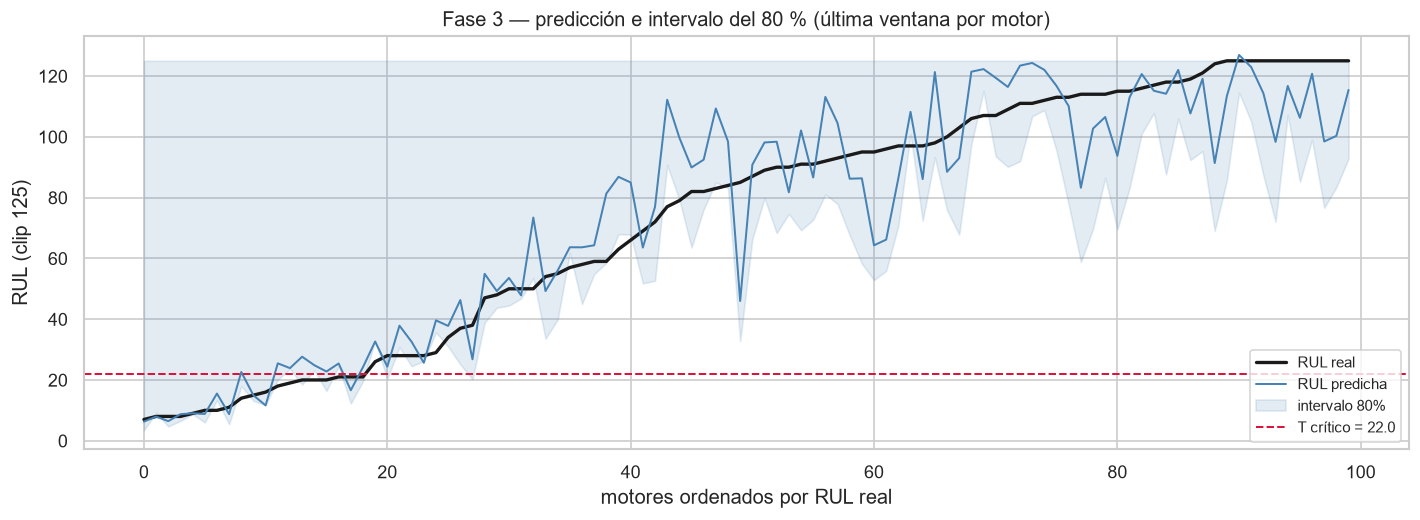

=== comparación de reglas de alarma (test, 100 motores) ===


,Regla,alarmas,recall,precision,coste
4,q10 < T*,18.0,100.0,50.0,9.0
0,media < T*,11.0,88.9,72.7,23.0
5,media < T* o q10 < 15,11.0,88.9,72.7,23.0
3,q10 < 15,11.0,88.9,72.7,23.0
1,media < 15 (fijo),9.0,77.8,77.8,42.0
2,q90 < 30,0.0,0.0,0.0,180.0


regla elegida: q10 < T*


In [30]:
q = pd.read_csv('models/v3_quantile_FD001.csv')
pol = json.loads(pathlib.Path('models/alarm_policy.json').read_text(encoding='utf-8'))
real_q = q['RUL_real'].values
cover = float(np.mean((real_q >= q['q10'].values) & (real_q <= q['q90'].values)))
ancho = float(np.mean(q['q90'].values - q['q10'].values))
print(f'cobertura del intervalo 80%: {100*cover:.1f}%  | ancho medio: {ancho:.1f} ciclos')

orden = q.sort_values('RUL_real').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(orden.index, orden['RUL_real'], 'k-', lw=2, label='RUL real')
ax.plot(orden.index, orden['pred'], color='steelblue', lw=1.2, label='RUL predicha')
ax.fill_between(orden.index, orden['q10'], orden['q90'], color='steelblue', alpha=0.15,
                label='intervalo 80%')
ax.axhline(pol['T_crit'], color='crimson', ls='--', lw=1.2, label=f"T crítico = {pol['T_crit']}")
ax.set_xlabel('motores ordenados por RUL real')
ax.set_ylabel('RUL (clip 125)')
ax.set_title('Fase 3 — predicción e intervalo del 80 % (última ventana por motor)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

reglas = pd.DataFrame(pol['reglas']).T.reset_index().rename(columns={'index': 'Regla'})
print('=== comparación de reglas de alarma (test, 100 motores) ===')
display(reglas[['Regla', 'alarmas', 'recall', 'precision', 'coste']].sort_values('coste'))
print('regla elegida:', pol['regla_elegida'])


### 9d. Fase 4 — transferencia a FD002 (6 condiciones) y FD004 (6 condiciones, 2 modos de fallo)

Mismo pipeline, recalibrando el umbral por coste en cada dataset. Se comparan solo los
modelos tabulares: la LSTM se reentrena únicamente en FD001 y FD002 (coste de cómputo).


=== FASE 4: transferencia del pipeline ===


,Dataset,Modelo,RMSE val/OOF,RMSE test,MAE test,T*,Recall @T*,Prec @T*,Alarmas
0,FD001,LightGBM,12.88,13.50,10.21,22.0,88.9,72.7,11
1,FD001,RandomForest,14.92,14.68,11.77,27.0,88.9,57.1,14
2,FD001,LinearRegression,14.11,14.76,11.27,30.5,100.0,45.0,20
3,FD001,LSTM 2x100-50 (holdout por motor),17.75,22.92,16.35,17.0,100.0,40.9,22
4,FD002,LinearRegression,16.90,15.41,12.58,32.5,97.6,75.5,53
5,FD002,LSTM 2x100-50 (holdout por motor),17.41,17.36,13.29,22.0,95.1,69.6,56
6,FD002,LightGBM,18.86,17.52,14.06,42.5,90.2,54.4,68
7,FD004,LinearRegression,18.12,17.83,14.40,39.0,96.9,63.3,49
8,FD004,LightGBM,19.25,20.65,16.83,45.0,84.4,45.8,59



RMSE test por dataset (features de salud):


Dataset,FD001,FD002,FD004
Modelo,,,
LSTM 2x100-50 (holdout por motor),22.92,17.36,NaN
LightGBM,13.50,17.52,20.65
LinearRegression,14.76,15.41,17.83
RandomForest,14.68,NaN,NaN


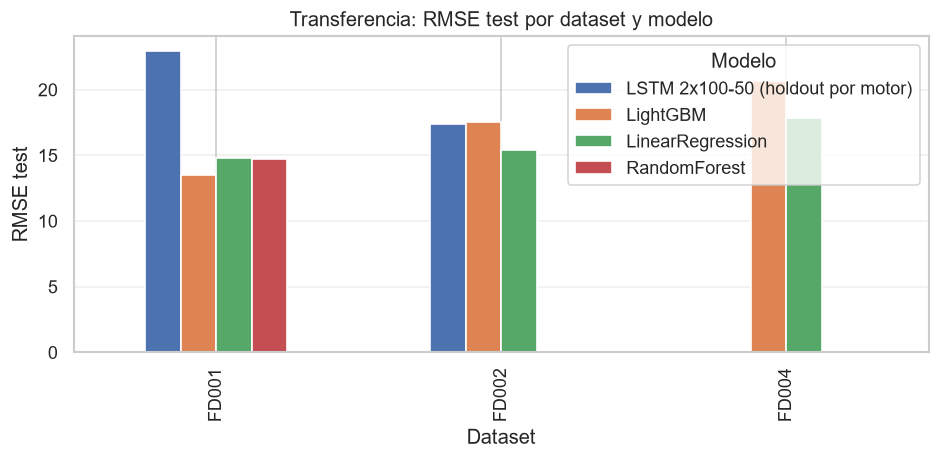

In [31]:
cols_trans = ['Dataset', 'Modelo', 'RMSE val/OOF', 'RMSE test', 'MAE test', 'T*',
              'Recall @T*', 'Prec @T*', 'Alarmas']
trans = tab_v3[tab_v3['Features'] == 'health'][cols_trans].copy()
print('=== FASE 4: transferencia del pipeline ===')
display(trans.sort_values(['Dataset', 'RMSE test']).reset_index(drop=True))

piv = tab_v3[tab_v3['Features'] == 'health'].pivot_table(
    index='Modelo', columns='Dataset', values='RMSE test')
print('\nRMSE test por dataset (features de salud):')
display(piv.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
piv.T.plot(kind='bar', ax=ax)
ax.set_ylabel('RMSE test')
ax.set_title('Transferencia: RMSE test por dataset y modelo')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### 9e. Fase 5 — sistema: inferencia, política y drift

`scripts/predict.py` carga `models/v3_bundle.joblib` (modelo + quantiles + features + versión)
y `models/alarm_policy.json`, y devuelve RUL, intervalo, alarma y **coste esperado de la decisión**.
Para drift: PSI **a nivel de flota** (comparar un solo motor contra la flota mide heterogeneidad,
no drift) y, por motor, % de valores fuera del rango [p01, p99] de entrenamiento.


In [32]:
import predict
importlib.reload(predict)

_, te5, _ = v3_core.load_fd('FD001')
for eid in (1, 3, 20):
    g = te5[te5['engine_id'] == eid]
    r = predict.predict(g)
    print(f'motor {eid:3d} -> RUL {r["rul"]:6.1f} [{r["q10"]:5.1f}, {r["q90"]:5.1f}]  '
          f'{r["alerta"]:8s} coste_esperado={r["coste_esperado"]:.2f}')

inf, met = predict.report('FD001')
print('\ninforme batch (100 motores):', met)
display(inf.head(5))

dfleet = predict.drift_batch(te5)
print(f"\ndrift de flota -> PSI max {dfleet['psi_max']:.3f} en {dfleet['peor_sensor']} "
      f"(alerta={dfleet['alerta_drift']}, n={dfleet['n_filas']})")
o = predict.out_of_range(te5[te5['engine_id'] == 66])
print(f"motor 66 fuera de rango: {o['peor_pct']:.1f}% en {o['peor_sensor']} (alerta={o['alerta']})")


motor   1 -> RUL  122.0 [108.8, 125.0]  VERDE    coste_esperado=0.40
motor   3 -> RUL   63.6 [ 51.8, 125.0]  VERDE    coste_esperado=0.40
motor  20 -> RUL   11.6 [ 11.7, 125.0]  ROJO     coste_esperado=1.00

informe batch (100 motores): {'n': 100, 'ROJO': 11, 'rojo_reales': 9, 'tp': 8, 'recall': 88.9, 'precision': 72.7}


,engine_id,cycle,RUL_real,RUL_pred,q10,q90,alerta,coste_esperado
0,1,31,112.0,122.0,108.8,125.0,VERDE,0.4
1,2,49,98.0,121.3,93.3,125.0,VERDE,0.4
2,3,126,69.0,63.6,51.8,125.0,VERDE,0.4
3,4,106,82.0,89.9,63.6,125.0,VERDE,0.4
4,5,98,91.0,102.1,69.3,125.0,VERDE,0.4



drift de flota -> PSI max 0.077 en s4 (alerta=False, n=3000)
motor 66 fuera de rango: 3.3% en s3 (alerta=False)


### 9f. Limitaciones de la v3 (dichas antes de que las pregunte nadie)

- **La `q90 < 30` no funciona**: el intervalo del 80 % mide ~65 ciclos de ancho, así que casi ningún
  motor queda por debajo del umbral. La incertidumbre sirve para priorizar, no para disparar alarmas sola.
- **El umbral se mueve con el dataset**: T* = 22 en FD001, 42.5 en FD002, 45 en FD004. No es transportable
  sin recalibrar (y recalibrar exige fallos reales).
- **OOF mide ventanas, test mide motores**: siguen siendo unidades distintas; el OOF es más pesimista.
- **FD002/FD004 con 1 seed y 3 folds**: sin barra de error. Sirven para ver si transfiere, no para decidir.
- **La LSTM** solo se reentrena en FD001/FD002; en FD004 no se ejecutó por coste (~20 min).
- Un **split temporal** de la RNN se probó y se descartó: validaba bien (14.5) pero en test daba 63,
  porque el tramo final de cada motor tiene un rango de RUL estrecho y el modelo no aprende a distinguir
  motores sanos. El holdout por motor sí cubre todo el rango.
- **El coste 20:1 es una suposición**, no un dato de planta. Cambiarlo mueve T* y el recall.


## 10. Conclusiones (v2 — con los números de esta ejecución)

### Tabla final

| Modelo | RMSE train | RMSE test | MAE test | Tiempo (s) | n motores |
|---|---|---|---|---|---|
| XGBoost baseline (por ciclo, media de ventana) | 14.02 | 26.16 | 20.27 | — | 100 |
| Random Forest (ventana aplanada) | 10.73 | 16.53 | 12.17 | 111.4 | 100 |
| **LightGBM (ventana aplanada)** | **7.34** | **13.42** | **10.33** | **7.7** | **100** |
| Linear Regression (ventana aplanada) | 16.61 | 15.94 | 13.07 | 1.9 | 100 |
| LSTM 2 capas 100-50 (baseline, w=30) | 11.24 | 15.14 | 11.77 | — | 100 |
| LSTM mejor variante (C, w=50) | 12.95 | 15.57 | 10.97 | 213.6 | 93 |


Ganador: **LightGBM** con RMSE test 13.42. Orden completo: LightGBM (13.42) < LSTM 2 capas (15.14) < LSTM mejor variante (15.57) < Linear Regression (15.94) < Random Forest (16.53) < XGBoost baseline (26.16).

### Variantes LSTM

| Variante | RMSE train | RMSE test (sus motores) | RMSE test (mismo n=93) | MAE test | n |
|---|---|---|---|---|---|
| A: LSTM 3 capas 100-64-32 + Dropout 0.2 (w=30) | 10.38 | 15.91 | 16.24 | 11.27 | 100 |
| B: Bidirectional LSTM 100-50 + Dropout 0.2 (w=30) | 9.77 | 15.47 | 15.69 | 10.89 | 100 |
| C: LSTM 2 capas 100-50 + Dropout 0.2 (w=50) | 12.95 | 15.57 | 15.57 | 10.97 | 93 |

La variante elegida es la **C: LSTM 2 capas 100-50 + Dropout 0.2 (w=50)** (RMSE test 15.57 sobre 93 motores,
entrenada 20 epochs). No baja de 15: el objetivo RMSE < 15 **no se cumple** en ninguna variante.
La ventana de 50 ciclos solo existe para 93 de 100 motores, por eso la comparación se hace
también a igual `n`; aun así no mejora al baseline de 2 capas con w=30 (15.14).

### 1. ¿Por qué el LSTM gana al XGBoost aquí?

Al baseline **sí** le gana, y con margen: 26.16 → 15.14 de RMSE.
Pero la razón no es "la recurrencia" sino **qué información ve el modelo**:

- El XGBoost baseline predice **ciclo a ciclo** y en test se promedia la ventana: ve 24 valores sueltos,
  sin saber si el motor está al principio o al final de su vida. Su error se dispara en los motores
  sanos (predice RUL bajo donde debería predecir 125): de ahí que su semáforo no marque **ni un ROJO**
  y falle el 24 % de las zonas.
- Cuando un GBDT ve **la misma ventana aplanada** (720 features), el problema se estrecha: LightGBM
  baja a 13.42 (mejor que cualquier LSTM), Random Forest se queda en
  16.53 (peor, mismo orden) y Linear Regression en 15.94.

Conclusión honesta: **la ventaja sobre el baseline viene de la ventana, no de la arquitectura**.
En FD001 (1 condición, 1 modo de fallo, 100 motores, 20 k ciclos) la señal está en la *forma* de la
ventana y LightGBM la explota mejor que el LSTM, con 7.7 s de entrenamiento frente a
213-361 s por variante LSTM.

### 2. Por qué en AI4I el LSTM perdía

AI4I no es una trayectoria monótona hacia el fallo: es un problema con `type` categórico,
temperaturas, par y desgaste, con target binario y ruido de medición. Allí:

- las features tabulares ya separan bien sin explotar orden temporal;
- el GBDT maneja categóricas e interacciones sin esfuerzo, el LSTM necesita codificarlas y secuenciarlas;
- con pocas muestras por unidad, la recurrencia solo añade varianza.

Resultado: en AI4I el LSTM no aportaba y el GBDT ganaba; aquí pasa algo parecido en cuanto el GBDT
recibe la ventana. **El patrón se repite: la secuencia ayuda cuando aporta información que el modelo
tabular no tiene; si el tabular ya la tiene, el LSTM solo cuesta.**

### 3. Qué modelo usaría en producción

Para este FD001, con estos números: **LightGBM** (RMSE 13.42, MAE 10.33,
7.7 s de entrenamiento, inferencia en milisegundos) y el semáforo encima. Razones:

- mismo rendimiento o mejor que el LSTM, sin GPU ni secuencias servidas;
- reentrenar y versionar es trivial frente a un `.h5` (y aquí `lstm_FD001_best.h5` pesa por arquitectura);
- el semáforo acierta 89.0 % de las zonas críticas con LightGBM.

LSTM solo si el problema real exige modelar dependencias largas que la ventana aplanada no captura
o si ya hay infraestructura de serving para modelos secuenciales.

### 4. Semáforo (RUL < 15 ROJO, < 30 AMARILLO, resto VERDE)

Real: **9 ROJO / 16 AMARILLO / 75 VERDE** (n=100).

| Modelo | ROJO | AMARILLO | VERDE | Zona correcta |
|---|---|---|---|---|
| XGBoost | 0 | 4 | 96 | 76/100 (76.0%) |
| Random Forest | 7 | 11 | 82 | 85/100 (85.0%) |
| LightGBM | 10 | 11 | 79 | 89/100 (89.0%) |
| Linear Regression | 8 | 6 | 86 | 87/100 (87.0%) |
| LSTM 2 capas | 7 | 12 | 81 | 90/100 (90.0%) |
| LSTM best (50 ciclos) | 11 | 15 | 67 | 84/93 (90.3%) |

Ojo con la métrica: acertar zona no es acertar RUL. El LSTM acierta más zona pero **sobreestima**
en los motores verdes; LightGBM es el que más ROJOS marca de verdad a tiempo
(10 detectados frente a 9 reales).

### 5. Limitaciones de esta medición

- Test evaluado solo en la **última ventana** de cada motor (n=100); la variante w=50 solo cubre 93.
- Seed única (42): las diferencias de 1-2 puntos de RMSE entre LSTM/RF/LR están dentro del ruido.
- RUL recortado a 125: los motores sanos nunca se evalúan en su RUL real (>125).
- TensorFlow no es determinista bit a bit; repetir la ejecución mueve las cifras de las variantes.
- El CSV por motor está en `models/test_eval_ultima_ventana.csv` (pred_xgb, pred_lstm, pred_rf,
  pred_lgb, pred_lr, pred_lstm_best) y las métricas crudas en `models/v2_metrics.json`.
